<a href="https://colab.research.google.com/github/uvindu827/J26-DS-350/blob/Indhi_Component2_CHL_Forecast/03_three_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ======================================================================
# STEP 31.9P-15 — FAIR THREE-MODEL COMPARISON
# RANDOM FOREST vs XGBOOST vs CNN-LSTM
# ======================================================================

import os
import json
import glob
import pandas as pd
import numpy as np

from pathlib import Path

# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

MODELS_DIR = PROJECT_DIR / "06_models"

RF_DIR = MODELS_DIR / "01_Random_Forest"
XGB_DIR = MODELS_DIR / "02_XGBoost"
CNN_DIR = MODELS_DIR / "03_CNN_LSTM"

COMPARISON_DIR = MODELS_DIR / "15_three_model_comparison"

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("STEP 31.9P-15 — FAIR THREE-MODEL COMPARISON")
print("=" * 70)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nComparison directory:")
print(COMPARISON_DIR)


# ======================================================================
# HELPER FUNCTION — FIND CSV FILE
# ======================================================================

def find_csv(directory, keywords):
    """
    Search recursively for CSV files containing all requested keywords.
    """

    csv_files = list(directory.rglob("*.csv"))

    matches = []

    for file in csv_files:

        name = file.name.lower()

        if all(keyword.lower() in name for keyword in keywords):
            matches.append(file)

    return matches


# ======================================================================
# SEARCH FOR FINAL TEST METRIC FILES
# ======================================================================

print("\n" + "=" * 70)
print("SEARCHING FOR FINAL TEST METRICS")
print("=" * 70)


rf_candidates = find_csv(
    RF_DIR,
    ["test", "metric"]
)

xgb_candidates = find_csv(
    XGB_DIR,
    ["test", "metric"]
)

cnn_candidates = find_csv(
    CNN_DIR,
    ["test", "metric"]
)


print("\nRandom Forest metric candidates:")
for f in rf_candidates:
    print(" -", f)

print("\nXGBoost metric candidates:")
for f in xgb_candidates:
    print(" -", f)

print("\nCNN-LSTM metric candidates:")
for f in cnn_candidates:
    print(" -", f)


# ======================================================================
# SELECT FINAL METRIC FILES
# ======================================================================

def choose_final_metric_file(candidates, preferred_names):

    # First try exact preferred filenames
    for preferred in preferred_names:

        for file in candidates:

            if file.name.lower() == preferred.lower():
                return file

    # Otherwise use the first candidate containing FINAL
    final_candidates = [
        f for f in candidates
        if "final" in f.name.lower()
    ]

    if len(final_candidates) > 0:
        return final_candidates[0]

    if len(candidates) > 0:
        return candidates[0]

    return None


rf_metrics_file = choose_final_metric_file(
    rf_candidates,
    [
        "RANDOM_FOREST_FINAL_TEST_METRICS.csv",
        "RF_FINAL_TEST_METRICS.csv",
        "random_forest_final_test_metrics.csv"
    ]
)

xgb_metrics_file = choose_final_metric_file(
    xgb_candidates,
    [
        "XGBoost_FINAL_TEST_METRICS.csv"
    ]
)

cnn_metrics_file = choose_final_metric_file(
    cnn_candidates,
    [
        "CNN_LSTM_FINAL_TEST_METRICS.csv"
    ]
)


print("\n" + "=" * 70)
print("SELECTED FINAL TEST METRIC FILES")
print("=" * 70)

print("\nRandom Forest:")
print(rf_metrics_file)

print("\nXGBoost:")
print(xgb_metrics_file)

print("\nCNN-LSTM:")
print(cnn_metrics_file)


# ======================================================================
# SAFETY CHECK
# ======================================================================

if rf_metrics_file is None:
    raise FileNotFoundError(
        "Random Forest final test metric CSV could not be located."
    )

if xgb_metrics_file is None:
    raise FileNotFoundError(
        "XGBoost final test metric CSV could not be located."
    )

if cnn_metrics_file is None:
    raise FileNotFoundError(
        "CNN-LSTM final test metric CSV could not be located."
    )


print("\n✓ All three final metric files located.")


# ======================================================================
# LOAD METRICS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING FINAL TEST METRICS")
print("=" * 70)


rf_metrics = pd.read_csv(rf_metrics_file)
xgb_metrics = pd.read_csv(xgb_metrics_file)
cnn_metrics = pd.read_csv(cnn_metrics_file)


print("\nRandom Forest metrics:")
print(rf_metrics.to_string(index=False))

print("\nXGBoost metrics:")
print(xgb_metrics.to_string(index=False))

print("\nCNN-LSTM metrics:")
print(cnn_metrics.to_string(index=False))


# ======================================================================
# STANDARDISE METRIC TABLE
# ======================================================================

def standardise_metrics(df, model_name):

    result = df.copy()

    result["model"] = model_name

    return result


rf_standard = standardise_metrics(
    rf_metrics,
    "Random Forest"
)

xgb_standard = standardise_metrics(
    xgb_metrics,
    "XGBoost"
)

cnn_standard = standardise_metrics(
    cnn_metrics,
    "CNN-LSTM"
)


comparison_raw = pd.concat(
    [
        rf_standard,
        xgb_standard,
        cnn_standard
    ],
    ignore_index=True
)


# ======================================================================
# SAVE RAW COMPARISON
# ======================================================================

raw_output = (
    COMPARISON_DIR /
    "three_model_final_test_metrics_raw.csv"
)

comparison_raw.to_csv(
    raw_output,
    index=False
)

print("\nRaw comparison saved:")
print(raw_output)


# ======================================================================
# CREATE CLEAN COMPARISON TABLE
# ======================================================================

print("\n" + "=" * 70)
print("CREATING FAIR COMPARISON TABLE")
print("=" * 70)


# The following function attempts to extract metrics regardless
# of whether the metric file is stored vertically or horizontally.

def extract_metric(df, possible_names):

    # --------------------------------------------------------------
    # Case 1 — metric/value format
    # --------------------------------------------------------------

    lower_columns = {
        str(c).lower(): c
        for c in df.columns
    }

    metric_column = None
    value_column = None

    for name in ["metric", "measure", "name"]:
        if name in lower_columns:
            metric_column = lower_columns[name]
            break

    for name in ["value", "score", "result"]:
        if name in lower_columns:
            value_column = lower_columns[name]
            break

    if metric_column is not None and value_column is not None:

        metrics_lower = (
            df[metric_column]
            .astype(str)
            .str.lower()
            .str.replace(" ", "_")
        )

        for possible in possible_names:

            possible_lower = (
                possible.lower()
                .replace(" ", "_")
            )

            mask = metrics_lower == possible_lower

            if mask.any():

                value = pd.to_numeric(
                    df.loc[mask, value_column],
                    errors="coerce"
                ).iloc[0]

                return value

    # --------------------------------------------------------------
    # Case 2 — metric stored directly as a column
    # --------------------------------------------------------------

    for column in df.columns:

        normalised = (
            str(column)
            .lower()
            .replace(" ", "_")
        )

        for possible in possible_names:

            possible_lower = (
                possible.lower()
                .replace(" ", "_")
            )

            if normalised == possible_lower:

                value = pd.to_numeric(
                    df[column],
                    errors="coerce"
                )

                if len(value) > 0:
                    return value.iloc[0]

    return np.nan


# ======================================================================
# EXTRACT CORE METRICS
# ======================================================================

models = {
    "Random Forest": rf_metrics,
    "XGBoost": xgb_metrics,
    "CNN-LSTM": cnn_metrics
}


comparison_rows = []


for model_name, df in models.items():

    row = {

        "model": model_name,

        # Original CHL
        "original_MAE": extract_metric(
            df,
            ["MAE", "original_MAE", "original_chl_MAE"]
        ),

        "original_RMSE": extract_metric(
            df,
            ["RMSE", "original_RMSE", "original_chl_RMSE"]
        ),

        "original_R2": extract_metric(
            df,
            ["R2", "R²", "original_R2", "original_chl_R2"]
        ),

        "original_Bias": extract_metric(
            df,
            ["Bias", "Mean Bias", "original_Bias"]
        ),

        # Log1p CHL
        "log1p_MAE": extract_metric(
            df,
            ["log_MAE", "log1p_MAE", "log1p_chl_MAE"]
        ),

        "log1p_RMSE": extract_metric(
            df,
            ["log_RMSE", "log1p_RMSE", "log1p_chl_RMSE"]
        ),

        "log1p_R2": extract_metric(
            df,
            ["log_R2", "log1p_R2", "log1p_chl_R2"]
        ),

        "log1p_Bias": extract_metric(
            df,
            ["log_Bias", "log1p_Bias", "log1p_chl_Bias"]
        )
    }

    comparison_rows.append(row)


comparison = pd.DataFrame(
    comparison_rows
)


# ======================================================================
# DISPLAY CORE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("CORE THREE-MODEL TEST COMPARISON")
print("=" * 70)

print(
    comparison.to_string(index=False)
)


# ======================================================================
# SAVE CORE COMPARISON
# ======================================================================

core_output = (
    COMPARISON_DIR /
    "three_model_core_test_comparison.csv"
)

comparison.to_csv(
    core_output,
    index=False
)

print("\nCore comparison saved:")
print(core_output)


# ======================================================================
# BEST MODEL BY EACH METRIC
# ======================================================================

print("\n" + "=" * 70)
print("METRIC-BY-METRIC WINNERS")
print("=" * 70)


metric_directions = {

    "original_MAE": "lower",
    "original_RMSE": "lower",
    "original_R2": "higher",
    "original_Bias": "absolute_lower",

    "log1p_MAE": "lower",
    "log1p_RMSE": "lower",
    "log1p_R2": "higher",
    "log1p_Bias": "absolute_lower"
}


winner_rows = []


for metric, direction in metric_directions.items():

    values = pd.to_numeric(
        comparison[metric],
        errors="coerce"
    )

    if values.notna().sum() == 0:
        winner = "Not available"

    else:

        if direction == "lower":
            index = values.idxmin()

        elif direction == "higher":
            index = values.idxmax()

        elif direction == "absolute_lower":
            index = values.abs().idxmin()

        winner = comparison.loc[index, "model"]

    winner_rows.append(
        {
            "metric": metric,
            "best_model": winner
        }
    )


winners = pd.DataFrame(winner_rows)

print(
    winners.to_string(index=False)
)


winner_output = (
    COMPARISON_DIR /
    "three_model_metric_winners.csv"
)

winners.to_csv(
    winner_output,
    index=False
)


# ======================================================================
# MODEL RANKING
# ======================================================================

print("\n" + "=" * 70)
print("MODEL RANKING")
print("=" * 70)


# Rank only metrics that are actually available.
# Lower MAE/RMSE = better.
# Higher R2 = better.
# Smaller absolute bias = better.

ranking = comparison[
    [
        "model",
        "original_MAE",
        "original_RMSE",
        "original_R2",
        "original_Bias",
        "log1p_MAE",
        "log1p_RMSE",
        "log1p_R2",
        "log1p_Bias"
    ]
].copy()


for metric in [
    "original_MAE",
    "original_RMSE",
    "log1p_MAE",
    "log1p_RMSE"
]:

    ranking[metric + "_rank"] = (
        ranking[metric]
        .rank(
            ascending=True,
            method="min"
        )
    )


for metric in [
    "original_R2",
    "log1p_R2"
]:

    ranking[metric + "_rank"] = (
        ranking[metric]
        .rank(
            ascending=False,
            method="min"
        )
    )


for metric in [
    "original_Bias",
    "log1p_Bias"
]:

    ranking[metric + "_rank"] = (
        ranking[metric]
        .abs()
        .rank(
            ascending=True,
            method="min"
        )
    )


rank_columns = [
    c for c in ranking.columns
    if c.endswith("_rank")
]


ranking["available_metric_count"] = (
    ranking[rank_columns]
    .notna()
    .sum(axis=1)
)

ranking["mean_rank"] = (
    ranking[rank_columns]
    .mean(axis=1)
)


ranking = ranking.sort_values(
    "mean_rank"
)


print(
    ranking[
        [
            "model",
            "available_metric_count",
            "mean_rank"
        ]
        + rank_columns
    ].to_string(index=False)
)


ranking_output = (
    COMPARISON_DIR /
    "three_model_ranking.csv"
)

ranking.to_csv(
    ranking_output,
    index=False
)


# ======================================================================
# FINAL INTERPRETATION — DATA DRIVEN
# ======================================================================

print("\n" + "=" * 70)
print("THREE-MODEL COMPARISON INTERPRETATION")
print("=" * 70)


if len(ranking) > 0:

    print(
        "\nRanking based on the available core test metrics:"
    )

    for position, (_, row) in enumerate(
        ranking.iterrows(),
        start=1
    ):

        print(
            f"{position}. {row['model']} "
            f"(mean metric rank: {row['mean_rank']:.3f})"
        )


print(
    "\nIMPORTANT:"
)

print(
    "This ranking is a statistical summary of the available "
    "test metrics only."
)

print(
    "It does NOT automatically mean that the top-ranked model "
    "is the scientifically best model."
)

print(
    "Extreme-CHL behaviour, prediction range, temporal stability, "
    "and the project's forecasting objective must also be considered."
)


# ======================================================================
# COMPARISON SUMMARY JSON
# ======================================================================

summary = {

    "comparison_stage":
        "31.9P-15",

    "models": [
        "Random Forest",
        "XGBoost",
        "CNN-LSTM"
    ],

    "training_performed":
        False,

    "test_data_used_for_new_training":
        False,

    "comparison_basis": [
        "Original CHL MAE",
        "Original CHL RMSE",
        "Original CHL R2",
        "Original CHL bias",
        "Log1p CHL MAE",
        "Log1p CHL RMSE",
        "Log1p CHL R2",
        "Log1p CHL bias"
    ],

    "ranking_warning":
        "Core statistical metrics should be considered together "
        "with extreme-event behaviour and scientific objectives."
}


summary_file = (
    COMPARISON_DIR /
    "three_model_comparison_summary.json"
)


with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


# ======================================================================
# COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-15 COMPLETE")
print("=" * 70)

print(
    "\n✓ Random Forest final results loaded."
)

print(
    "✓ XGBoost final results loaded."
)

print(
    "✓ CNN-LSTM final results loaded."
)

print(
    "✓ Core test metrics compared."
)

print(
    "✓ Metric-by-metric winners calculated."
)

print(
    "✓ Model ranking calculated."
)

print(
    "✓ Comparison files saved."
)

print(
    "\nComparison directory:"
)

print(
    COMPARISON_DIR
)

print(
    "\nIMPORTANT:"
)

print(
    "No model was retrained."
)

print(
    "No hyperparameters were changed."
)

print(
    "No new model selection was performed using test data."
)

STEP 31.9P-15 — FAIR THREE-MODEL COMPARISON

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Comparison directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison

SEARCHING FOR FINAL TEST METRICS

Random Forest metric candidates:

XGBoost metric candidates:
 - /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/evaluation/XGBoost_FINAL_TEST_METRICS.csv

CNN-LSTM metric candidates:
 - /content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/CNN_LSTM_FINAL_TEST_METRICS.csv

SELECTED FINAL TEST METRIC FILES

Random Forest:
None

XGBoost:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/evaluation/XGBoost_FINAL_TEST_METRICS.csv

CNN-LSTM:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/CNN_LSTM_FINAL_TEST_METRICS.csv


FileNotFoundError: Random Forest final test metric CSV could not be located.

In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

print("=" * 70)
print("RANDOM FOREST FILE SEARCH")
print("=" * 70)

# Search the entire project, not only the RF folder
all_files = list(PROJECT_DIR.rglob("*"))

print("\nFiles/folders containing 'random' or 'rf':")
print("-" * 70)

matches = []

for file in all_files:
    name = file.name.lower()

    if (
        "random" in name
        or "random_forest" in name
        or name.startswith("rf")
    ):
        matches.append(file)

if matches:
    for file in matches:
        print(file)
else:
    print("No matching Random Forest files found.")


print("\n" + "=" * 70)
print("ALL CSV FILES CONTAINING TEST / METRIC / SUMMARY")
print("=" * 70)

csv_matches = []

for file in all_files:

    if file.is_file() and file.suffix.lower() == ".csv":

        name = file.name.lower()

        if (
            "test" in name
            or "metric" in name
            or "summary" in name
        ):
            csv_matches.append(file)

if csv_matches:
    for file in csv_matches:
        print(file)
else:
    print("No matching CSV files found.")


print("\n" + "=" * 70)
print("RANDOM FOREST DIRECTORY CHECK")
print("=" * 70)

rf_dirs = [
    p for p in all_files
    if p.is_dir()
    and (
        "random" in p.name.lower()
        or "random_forest" in p.name.lower()
        or p.name.lower() == "01_random_forest"
    )
]

for directory in rf_dirs:
    print("\nDirectory:")
    print(directory)

    try:
        children = list(directory.iterdir())

        print("Contents:")

        for child in children:
            print("  ", child.name)

    except Exception as e:
        print("Could not read:", e)

RANDOM FOREST FILE SEARCH

Files/folders containing 'random' or 'rf':
----------------------------------------------------------------------
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_chlorophyll_model.joblib
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_training_configuration.csv
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_validation_predictions.csv
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_final_validation_summary.csv
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_final_validation_report.txt
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/01_Random_Forest_CHL_Forecasting.ipynb
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Fores

In [ ]:
# ======================================================================
# STEP 31.9P-15A
# RANDOM FOREST FINAL TEST EVALUATION
# ======================================================================
#
# Purpose:
#   Evaluate the ALREADY TRAINED Random Forest model on the untouched
#   final test dataset.
#
# IMPORTANT:
#   - No retraining
#   - No hyperparameter tuning
#   - No model modification
#   - Test data used ONLY for final evaluation
# ======================================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score,
    median_absolute_error
)

# ======================================================================
# PATHS
# ======================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

PREPROCESSING_DIR = (
    PROJECT_DIR / "05_model_preprocessing"
)

RF_DIR = (
    PROJECT_DIR / "06_models" / "01_Random_Forest"
)

RF_EVAL_DIR = RF_DIR / "evaluation"

RF_EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TEST_FILE = (
    PREPROCESSING_DIR /
    "final_model_ready_test.csv"
)

FEATURE_FILE = (
    PREPROCESSING_DIR /
    "final_model_feature_columns.csv"
)

MODEL_FILE = (
    RF_DIR /
    "random_forest_chlorophyll_model.joblib"
)

print("=" * 70)
print("STEP 31.9P-15A")
print("RANDOM FOREST FINAL TEST EVALUATION")
print("=" * 70)

print("\nProject:")
print(PROJECT_DIR)

print("\nTest dataset:")
print(TEST_FILE)

print("\nFeature list:")
print(FEATURE_FILE)

print("\nRandom Forest model:")
print(MODEL_FILE)


# ======================================================================
# FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

for name, path in {
    "Test dataset": TEST_FILE,
    "Feature list": FEATURE_FILE,
    "Random Forest model": MODEL_FILE
}.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", path.exists())

    if not path.exists():
        raise FileNotFoundError(
            f"Required file missing: {path}"
        )

print("\n✓ All required files found.")


# ======================================================================
# LOAD TEST DATA
# ======================================================================

print("\n" + "=" * 70)
print("LOADING FINAL TEST DATA")
print("=" * 70)

test_df = pd.read_csv(
    TEST_FILE
)

feature_df = pd.read_csv(
    FEATURE_FILE
)

# Identify feature column
if "feature" in feature_df.columns:
    feature_columns = (
        feature_df["feature"]
        .dropna()
        .tolist()
    )

elif "feature_name" in feature_df.columns:
    feature_columns = (
        feature_df["feature_name"]
        .dropna()
        .tolist()
    )

else:
    feature_columns = feature_df.iloc[:, 0].dropna().tolist()


print("\nTest shape:")
print(test_df.shape)

print("\nNumber of selected features:")
print(len(feature_columns))

print("\nTarget:")
print("chlorophyll_a_log1p")

print("\nOriginal target:")
print("chlorophyll_a")


# ======================================================================
# FEATURE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FEATURE EXISTENCE CHECK")
print("=" * 70)

missing_features = [
    feature
    for feature in feature_columns
    if feature not in test_df.columns
]

print("\nMissing features:")
print(len(missing_features))

if missing_features:
    print(missing_features)
    raise ValueError(
        "Required model features are missing from test data."
    )

print("✓ All selected features are available.")


# ======================================================================
# BUILD TEST INPUTS
# ======================================================================

X_test = test_df[
    feature_columns
].copy()

y_test_log = test_df[
    "chlorophyll_a_log1p"
].copy()

y_test_original = test_df[
    "chlorophyll_a"
].copy()


print("\n" + "=" * 70)
print("TEST INPUT SHAPES")
print("=" * 70)

print("\nX_test:")
print(X_test.shape)

print("\ny_test_log:")
print(y_test_log.shape)

print("\ny_test_original:")
print(y_test_original.shape)


# ======================================================================
# SAFETY CHECK
# ======================================================================

print("\n" + "=" * 70)
print("TEST INPUT SAFETY CHECK")
print("=" * 70)

print(
    "\nPredictor missing values:",
    int(X_test.isna().sum().sum())
)

print(
    "Log target missing values:",
    int(y_test_log.isna().sum())
)

print(
    "Original target missing values:",
    int(y_test_original.isna().sum())
)

print(
    "Predictor infinite values:",
    int(np.isinf(X_test.to_numpy()).sum())
)

if (
    X_test.isna().sum().sum() > 0
    or y_test_log.isna().sum() > 0
    or y_test_original.isna().sum() > 0
    or np.isinf(X_test.to_numpy()).sum() > 0
):
    raise ValueError(
        "Test input safety check failed."
    )

print("\n✓ Test inputs are clean.")


# ======================================================================
# LOAD ALREADY TRAINED MODEL
# ======================================================================

print("\n" + "=" * 70)
print("LOADING ALREADY TRAINED RANDOM FOREST")
print("=" * 70)

rf_model = joblib.load(
    MODEL_FILE
)

print("\nModel type:")
print(type(rf_model))

print("\n✓ Existing Random Forest model loaded.")
print("✓ NO retraining performed.")


# ======================================================================
# GENERATE FINAL TEST PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING FINAL TEST PREDICTIONS")
print("=" * 70)

print("\nTest rows:")
print(len(X_test))

y_pred_log = rf_model.predict(
    X_test
)

print("\n✓ Log1p predictions generated.")


# ======================================================================
# CONVERT BACK TO ORIGINAL CHL
# ======================================================================

print("\n" + "=" * 70)
print("CONVERTING PREDICTIONS TO ORIGINAL CHL")
print("=" * 70)

y_pred_original = np.expm1(
    y_pred_log
)

print("""
Random Forest output
        ↓
predicted log1p CHL
        ↓
expm1()
        ↓
predicted original CHL (mg/m³)
""")


# ======================================================================
# PREDICTION SAFETY
# ======================================================================

print("\n" + "=" * 70)
print("PREDICTION SANITY CHECK")
print("=" * 70)

print(
    "\nNaN predictions:",
    int(np.isnan(y_pred_log).sum())
)

print(
    "Infinite predictions:",
    int(np.isinf(y_pred_log).sum())
)

print(
    "NaN original predictions:",
    int(np.isnan(y_pred_original).sum())
)

print(
    "Infinite original predictions:",
    int(np.isinf(y_pred_original).sum())
)

if (
    np.isnan(y_pred_log).any()
    or np.isinf(y_pred_log).any()
    or np.isnan(y_pred_original).any()
    or np.isinf(y_pred_original).any()
):
    raise ValueError(
        "Prediction sanity check failed."
    )

print("\n✓ Predictions are valid.")


# ======================================================================
# PREDICTION RANGES
# ======================================================================

print("\n" + "=" * 70)
print("FINAL RANDOM FOREST TEST PREDICTION RANGE")
print("=" * 70)

print("\nActual log1p CHL:")
print("Minimum:", float(y_test_log.min()))
print("Maximum:", float(y_test_log.max()))

print("\nPredicted log1p CHL:")
print("Minimum:", float(y_pred_log.min()))
print("Maximum:", float(y_pred_log.max()))

print("\nActual original CHL:")
print(
    "Minimum:",
    float(y_test_original.min()),
    "mg/m³"
)

print(
    "Maximum:",
    float(y_test_original.max()),
    "mg/m³"
)

print("\nPredicted original CHL:")
print(
    "Minimum:",
    float(y_pred_original.min()),
    "mg/m³"
)

print(
    "Maximum:",
    float(y_pred_original.max()),
    "mg/m³"
)


# ======================================================================
# ORIGINAL CHL METRICS
# ======================================================================

original_mae = mean_absolute_error(
    y_test_original,
    y_pred_original
)

original_rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        y_pred_original
    )
)

original_r2 = r2_score(
    y_test_original,
    y_pred_original
)

original_median_ae = median_absolute_error(
    y_test_original,
    y_pred_original
)

original_bias = np.mean(
    y_pred_original -
    y_test_original
)

original_explained_variance = (
    explained_variance_score(
        y_test_original,
        y_pred_original
    )
)


# ======================================================================
# LOG1P METRICS
# ======================================================================

log_mae = mean_absolute_error(
    y_test_log,
    y_pred_log
)

log_rmse = np.sqrt(
    mean_squared_error(
        y_test_log,
        y_pred_log
    )
)

log_r2 = r2_score(
    y_test_log,
    y_pred_log
)

log_bias = np.mean(
    y_pred_log -
    y_test_log
)


# ======================================================================
# DISPLAY ORIGINAL SCALE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("FINAL RANDOM FOREST TEST PERFORMANCE")
print("ORIGINAL CHL SCALE")
print("=" * 70)

print(
    f"MAE              : "
    f"{original_mae:.6f} mg/m³"
)

print(
    f"RMSE             : "
    f"{original_rmse:.6f} mg/m³"
)

print(
    f"R²               : "
    f"{original_r2:.6f}"
)

print(
    f"Median AE        : "
    f"{original_median_ae:.6f} mg/m³"
)

print(
    f"Mean Bias        : "
    f"{original_bias:.6f} mg/m³"
)

print(
    f"Explained Var.   : "
    f"{original_explained_variance:.6f}"
)


# ======================================================================
# DISPLAY LOG SCALE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("FINAL RANDOM FOREST TEST PERFORMANCE")
print("LOG1P CHL SCALE")
print("=" * 70)

print(
    f"Log MAE     : "
    f"{log_mae:.6f}"
)

print(
    f"Log RMSE    : "
    f"{log_rmse:.6f}"
)

print(
    f"Log R²      : "
    f"{log_r2:.6f}"
)

print(
    f"Log Bias    : "
    f"{log_bias:.6f}"
)


# ======================================================================
# PREDICTION DIRECTION
# ======================================================================

error = (
    y_pred_original -
    y_test_original
)

over_count = int(
    (error > 0).sum()
)

under_count = int(
    (error < 0).sum()
)

exact_count = int(
    (error == 0).sum()
)

total = len(error)


print("\n" + "=" * 70)
print("FINAL RANDOM FOREST TEST PREDICTION DIRECTION")
print("=" * 70)

print(
    f"Overpredictions : "
    f"{over_count:,} "
    f"({over_count / total * 100:.2f}%)"
)

print(
    f"Underpredictions: "
    f"{under_count:,} "
    f"({under_count / total * 100:.2f}%)"
)

print(
    f"Exact predictions: "
    f"{exact_count:,} "
    f"({exact_count / total * 100:.2f}%)"
)


# ======================================================================
# SAVE TEST PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("SAVING RANDOM FOREST TEST PREDICTIONS")
print("=" * 70)

prediction_columns = {}

# Preserve metadata where available
for column in [
    "date",
    "target_date",
    "latitude",
    "longitude"
]:

    if column in test_df.columns:
        prediction_columns[column] = test_df[
            column
        ].values


prediction_columns[
    "actual_chlorophyll_a"
] = y_test_original.values

prediction_columns[
    "actual_chlorophyll_a_log1p"
] = y_test_log.values

prediction_columns[
    "predicted_chlorophyll_a_log1p"
] = y_pred_log

prediction_columns[
    "predicted_chlorophyll_a"
] = y_pred_original


rf_test_predictions = pd.DataFrame(
    prediction_columns
)


prediction_file = (
    RF_DIR /
    "random_forest_test_predictions.csv"
)

rf_test_predictions.to_csv(
    prediction_file,
    index=False
)

print("\nSaved:")
print(prediction_file)

print("\nShape:")
print(rf_test_predictions.shape)


# ======================================================================
# SAVE FINAL TEST METRICS
# ======================================================================

print("\n" + "=" * 70)
print("SAVING RANDOM FOREST FINAL TEST METRICS")
print("=" * 70)

metrics_rows = [

    {
        "scale": "original_chl",
        "MAE": original_mae,
        "RMSE": original_rmse,
        "R2": original_r2,
        "Median_AE": original_median_ae,
        "Bias": original_bias,
        "Explained_Variance":
            original_explained_variance
    },

    {
        "scale": "log1p_chl",
        "MAE": log_mae,
        "RMSE": log_rmse,
        "R2": log_r2,
        "Median_AE": np.nan,
        "Bias": log_bias,
        "Explained_Variance": np.nan
    }
]


rf_final_metrics = pd.DataFrame(
    metrics_rows
)

metrics_file = (
    RF_EVAL_DIR /
    "RANDOM_FOREST_FINAL_TEST_METRICS.csv"
)

rf_final_metrics.to_csv(
    metrics_file,
    index=False
)

print("\nSaved:")
print(metrics_file)

print("\nMetrics:")
print(
    rf_final_metrics.to_string(
        index=False
    )
)


# ======================================================================
# SAVE SUMMARY
# ======================================================================

summary = {

    "model":
        "Random Forest",

    "evaluation":
        "Final Test Evaluation",

    "retraining":
        False,

    "hyperparameter_tuning":
        False,

    "test_used_for_training":
        False,

    "test_used_for_final_evaluation":
        True,

    "number_of_features":
        len(feature_columns),

    "target":
        "chlorophyll_a_log1p",

    "original_target":
        "chlorophyll_a",

    "original_chl": {

        "MAE":
            float(original_mae),

        "RMSE":
            float(original_rmse),

        "R2":
            float(original_r2),

        "Median_AE":
            float(original_median_ae),

        "Bias":
            float(original_bias),

        "Explained_Variance":
            float(original_explained_variance)
    },

    "log1p_chl": {

        "MAE":
            float(log_mae),

        "RMSE":
            float(log_rmse),

        "R2":
            float(log_r2),

        "Bias":
            float(log_bias)
    },

    "prediction_range": {

        "actual_max":
            float(y_test_original.max()),

        "predicted_max":
            float(y_pred_original.max())
    }
}


summary_file = (
    RF_EVAL_DIR /
    "RANDOM_FOREST_FINAL_TEST_SUMMARY.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


# ======================================================================
# COMPLETE
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-15A COMPLETE")
print("=" * 70)

print("\n✓ Existing Random Forest model loaded.")
print("✓ No retraining performed.")
print("✓ Final test dataset loaded.")
print("✓ Test predictions generated.")
print("✓ Log1p predictions converted using expm1().")
print("✓ Original CHL metrics calculated.")
print("✓ Log1p CHL metrics calculated.")
print("✓ Prediction range calculated.")
print("✓ Prediction direction calculated.")
print("✓ Test predictions saved.")
print("✓ Final RF test metrics saved.")
print("✓ Final RF test summary saved.")

print("\nFinal metrics:")
print(metrics_file)

print("\nTest predictions:")
print(prediction_file)

print("\nFinal summary:")
print(summary_file)

print("\n" + "=" * 70)
print("RANDOM FOREST FINAL TEST EVALUATION CLOSED")
print("=" * 70)

STEP 31.9P-15A
RANDOM FOREST FINAL TEST EVALUATION

Project:
/content/drive/MyDrive/Indhi_Marine_Research_Data

Test dataset:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_ready_test.csv

Feature list:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_feature_columns.csv

Random Forest model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_chlorophyll_model.joblib

REQUIRED FILE CHECK

Test dataset:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_ready_test.csv
Exists: True

Feature list:
/content/drive/MyDrive/Indhi_Marine_Research_Data/05_model_preprocessing/final_model_feature_columns.csv
Exists: True

Random Forest model:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_chlorophyll_model.joblib
Exists: True

✓ All required files found.

LOADING FINAL TEST DATA

Test shape:
(157998, 75)

Nu

In [ ]:
# ======================================================================
# STEP 31.9P-15B — FAIR THREE-MODEL FINAL TEST COMPARISON
# ======================================================================
#
# Purpose:
#   Compare the FINAL TEST performance of:
#       1. Random Forest
#       2. XGBoost
#       3. CNN-LSTM
#
# IMPORTANT:
#   - No model retraining
#   - No hyperparameter tuning
#   - No modification of trained models
#   - Test results are used only for final comparison
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

COMPARISON_DIR = (
    PROJECT_DIR /
    "06_models" /
    "15_three_model_comparison"
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ======================================================================
# MODEL METRIC FILES
# ======================================================================

RF_METRICS_FILE = (
    PROJECT_DIR /
    "06_models" /
    "01_Random_Forest" /
    "evaluation" /
    "RANDOM_FOREST_FINAL_TEST_METRICS.csv"
)

XGB_METRICS_FILE = (
    PROJECT_DIR /
    "06_models" /
    "02_XGBoost" /
    "evaluation" /
    "XGBoost_FINAL_TEST_METRICS.csv"
)

CNN_METRICS_FILE = (
    PROJECT_DIR /
    "06_models" /
    "03_CNN_LSTM" /
    "evaluation" /
    "CNN_LSTM_FINAL_TEST_METRICS.csv"
)


print("=" * 70)
print("STEP 31.9P-15B")
print("FAIR THREE-MODEL FINAL TEST COMPARISON")
print("=" * 70)

print("\nComparison directory:")
print(COMPARISON_DIR)


# ======================================================================
# REQUIRED FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TEST METRIC FILE CHECK")
print("=" * 70)

metric_files = {
    "Random Forest": RF_METRICS_FILE,
    "XGBoost": XGB_METRICS_FILE,
    "CNN-LSTM": CNN_METRICS_FILE
}

for model_name, path in metric_files.items():

    print(f"\n{model_name}:")
    print(path)
    print("Exists:", path.exists())

    if not path.exists():
        raise FileNotFoundError(
            f"{model_name} final test metrics not found:\n{path}"
        )

print("\n✓ All three final test metric files found.")


# ======================================================================
# LOAD METRICS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING FINAL TEST METRICS")
print("=" * 70)

rf_metrics = pd.read_csv(
    RF_METRICS_FILE
)

xgb_metrics = pd.read_csv(
    XGB_METRICS_FILE
)

cnn_metrics = pd.read_csv(
    CNN_METRICS_FILE
)

print("\nRandom Forest metrics:")
print(rf_metrics.to_string(index=False))

print("\nXGBoost metrics:")
print(xgb_metrics.to_string(index=False))

print("\nCNN-LSTM metrics:")
print(cnn_metrics.to_string(index=False))


# ======================================================================
# CHECK REQUIRED SCALE ROWS
# ======================================================================

print("\n" + "=" * 70)
print("METRIC SCALE CHECK")
print("=" * 70)

for model_name, df in [
    ("Random Forest", rf_metrics),
    ("XGBoost", xgb_metrics),
    ("CNN-LSTM", cnn_metrics)
]:

    if "scale" not in df.columns:
        raise ValueError(
            f"{model_name} metric file does not contain 'scale'."
        )

    print(
        f"\n{model_name} scales:",
        df["scale"].tolist()
    )


# ======================================================================
# HELPER FUNCTION
# ======================================================================

def get_metric(
    df,
    scale_name,
    metric_name
):
    """
    Safely retrieve a metric for a specified scale.
    """

    rows = df[
        df["scale"].astype(str).str.lower()
        == scale_name.lower()
    ]

    if rows.empty:
        return np.nan

    if metric_name not in rows.columns:
        return np.nan

    value = rows.iloc[0][metric_name]

    if pd.isna(value):
        return np.nan

    return float(value)


# ======================================================================
# BUILD COMPARISON TABLE
# ======================================================================

comparison_rows = []

for model_name, df in [
    ("Random Forest", rf_metrics),
    ("XGBoost", xgb_metrics),
    ("CNN-LSTM", cnn_metrics)
]:

    comparison_rows.append({

        "model":
            model_name,

        # Original CHL
        "original_MAE":
            get_metric(
                df,
                "original_chl",
                "MAE"
            ),

        "original_RMSE":
            get_metric(
                df,
                "original_chl",
                "RMSE"
            ),

        "original_R2":
            get_metric(
                df,
                "original_chl",
                "R2"
            ),

        "original_Median_AE":
            get_metric(
                df,
                "original_chl",
                "Median_AE"
            ),

        "original_Bias":
            get_metric(
                df,
                "original_chl",
                "Bias"
            ),

        "original_Explained_Variance":
            get_metric(
                df,
                "original_chl",
                "Explained_Variance"
            ),

        # Log1p CHL
        "log1p_MAE":
            get_metric(
                df,
                "log1p_chl",
                "MAE"
            ),

        "log1p_RMSE":
            get_metric(
                df,
                "log1p_chl",
                "RMSE"
            ),

        "log1p_R2":
            get_metric(
                df,
                "log1p_chl",
                "R2"
            ),

        "log1p_Bias":
            get_metric(
                df,
                "log1p_chl",
                "Bias"
            )
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


# ======================================================================
# DISPLAY FAIR COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("FINAL THREE-MODEL TEST COMPARISON")
print("=" * 70)

print(
    comparison_df.to_string(
        index=False
    )
)


# ======================================================================
# ORIGINAL CHL RANKINGS
# ======================================================================

print("\n" + "=" * 70)
print("ORIGINAL CHL PERFORMANCE RANKINGS")
print("=" * 70)


# Lower MAE = better
mae_ranking = (
    comparison_df
    .sort_values(
        "original_MAE",
        ascending=True
    )
    [["model", "original_MAE"]]
    .reset_index(drop=True)
)

mae_ranking["MAE_rank"] = (
    np.arange(len(mae_ranking)) + 1
)

print("\nMAE ranking:")
print(
    mae_ranking.to_string(
        index=False
    )
)


# Lower RMSE = better
rmse_ranking = (
    comparison_df
    .sort_values(
        "original_RMSE",
        ascending=True
    )
    [["model", "original_RMSE"]]
    .reset_index(drop=True)
)

rmse_ranking["RMSE_rank"] = (
    np.arange(len(rmse_ranking)) + 1
)

print("\nRMSE ranking:")
print(
    rmse_ranking.to_string(
        index=False
    )
)


# Higher R² = better
r2_ranking = (
    comparison_df
    .sort_values(
        "original_R2",
        ascending=False
    )
    [["model", "original_R2"]]
    .reset_index(drop=True)
)

r2_ranking["R2_rank"] = (
    np.arange(len(r2_ranking)) + 1
)

print("\nR² ranking:")
print(
    r2_ranking.to_string(
        index=False
    )
)


# ======================================================================
# LOG1P RANKINGS
# ======================================================================

print("\n" + "=" * 70)
print("LOG1P CHL PERFORMANCE RANKINGS")
print("=" * 70)


log_mae_ranking = (
    comparison_df
    .sort_values(
        "log1p_MAE",
        ascending=True
    )
    [["model", "log1p_MAE"]]
    .reset_index(drop=True)
)

log_mae_ranking["MAE_rank"] = (
    np.arange(len(log_mae_ranking)) + 1
)

print("\nLog1p MAE ranking:")
print(
    log_mae_ranking.to_string(
        index=False
    )
)


log_rmse_ranking = (
    comparison_df
    .sort_values(
        "log1p_RMSE",
        ascending=True
    )
    [["model", "log1p_RMSE"]]
    .reset_index(drop=True)
)

log_rmse_ranking["RMSE_rank"] = (
    np.arange(len(log_rmse_ranking)) + 1
)

print("\nLog1p RMSE ranking:")
print(
    log_rmse_ranking.to_string(
        index=False
    )
)


log_r2_ranking = (
    comparison_df
    .sort_values(
        "log1p_R2",
        ascending=False
    )
    [["model", "log1p_R2"]]
    .reset_index(drop=True)
)

log_r2_ranking["R2_rank"] = (
    np.arange(len(log_r2_ranking)) + 1
)

print("\nLog1p R² ranking:")
print(
    log_r2_ranking.to_string(
        index=False
    )
)


# ======================================================================
# SIMPLE OVERALL RANK
# ======================================================================

print("\n" + "=" * 70)
print("OVERALL RANKING")
print("=" * 70)

ranking = comparison_df[
    [
        "model",
        "original_MAE",
        "original_RMSE",
        "original_R2"
    ]
].copy()

ranking["MAE_rank"] = (
    ranking["original_MAE"]
    .rank(
        ascending=True,
        method="min"
    )
)

ranking["RMSE_rank"] = (
    ranking["original_RMSE"]
    .rank(
        ascending=True,
        method="min"
    )
)

ranking["R2_rank"] = (
    ranking["original_R2"]
    .rank(
        ascending=False,
        method="min"
    )
)

ranking["average_rank"] = (
    ranking[
        [
            "MAE_rank",
            "RMSE_rank",
            "R2_rank"
        ]
    ].mean(axis=1)
)

ranking = ranking.sort_values(
    "average_rank"
).reset_index(drop=True)

ranking["overall_rank"] = (
    np.arange(len(ranking)) + 1
)

print(
    ranking.to_string(
        index=False
    )
)


# ======================================================================
# BEST MODEL BY INDIVIDUAL METRIC
# ======================================================================

best_mae = comparison_df.loc[
    comparison_df["original_MAE"].idxmin(),
    "model"
]

best_rmse = comparison_df.loc[
    comparison_df["original_RMSE"].idxmin(),
    "model"
]

best_r2 = comparison_df.loc[
    comparison_df["original_R2"].idxmax(),
    "model"
]

best_log_mae = comparison_df.loc[
    comparison_df["log1p_MAE"].idxmin(),
    "model"
]

best_log_rmse = comparison_df.loc[
    comparison_df["log1p_RMSE"].idxmin(),
    "model"
]

best_log_r2 = comparison_df.loc[
    comparison_df["log1p_R2"].idxmax(),
    "model"
]


print("\n" + "=" * 70)
print("BEST MODEL BY METRIC")
print("=" * 70)

print("\nOriginal CHL:")
print("Best MAE  :", best_mae)
print("Best RMSE :", best_rmse)
print("Best R²   :", best_r2)

print("\nLog1p CHL:")
print("Best MAE  :", best_log_mae)
print("Best RMSE :", best_log_rmse)
print("Best R²   :", best_log_r2)


# ======================================================================
# SAVE COMPARISON TABLE
# ======================================================================

comparison_file = (
    COMPARISON_DIR /
    "three_model_final_test_comparison.csv"
)

comparison_df.to_csv(
    comparison_file,
    index=False
)

print("\n" + "=" * 70)
print("COMPARISON TABLE SAVED")
print("=" * 70)

print(comparison_file)


# ======================================================================
# SAVE RANKING
# ======================================================================

ranking_file = (
    COMPARISON_DIR /
    "three_model_overall_ranking.csv"
)

ranking.to_csv(
    ranking_file,
    index=False
)

print("\nOverall ranking saved:")
print(ranking_file)


# ======================================================================
# SAVE BEST-METRIC SUMMARY
# ======================================================================

best_summary = pd.DataFrame({

    "metric": [
        "Original CHL MAE",
        "Original CHL RMSE",
        "Original CHL R2",
        "Log1p CHL MAE",
        "Log1p CHL RMSE",
        "Log1p CHL R2"
    ],

    "best_model": [
        best_mae,
        best_rmse,
        best_r2,
        best_log_mae,
        best_log_rmse,
        best_log_r2
    ]
})

best_summary_file = (
    COMPARISON_DIR /
    "three_model_best_by_metric.csv"
)

best_summary.to_csv(
    best_summary_file,
    index=False
)

print("\nBest-by-metric summary saved:")
print(best_summary_file)


# ======================================================================
# CREATE ORIGINAL-SCALE COMPARISON FIGURE
# ======================================================================

print("\n" + "=" * 70)
print("CREATING ORIGINAL CHL COMPARISON FIGURE")
print("=" * 70)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


models = comparison_df["model"].tolist()

# --------------------------------------------------
# MAE
# --------------------------------------------------

axes[0].bar(
    models,
    comparison_df["original_MAE"]
)

axes[0].set_title(
    "Test MAE — Original CHL"
)

axes[0].set_ylabel(
    "MAE (mg/m³)"
)

axes[0].tick_params(
    axis="x",
    rotation=20
)


# --------------------------------------------------
# RMSE
# --------------------------------------------------

axes[1].bar(
    models,
    comparison_df["original_RMSE"]
)

axes[1].set_title(
    "Test RMSE — Original CHL"
)

axes[1].set_ylabel(
    "RMSE (mg/m³)"
)

axes[1].tick_params(
    axis="x",
    rotation=20
)


# --------------------------------------------------
# R²
# --------------------------------------------------

axes[2].bar(
    models,
    comparison_df["original_R2"]
)

axes[2].set_title(
    "Test R² — Original CHL"
)

axes[2].set_ylabel(
    "R²"
)

axes[2].tick_params(
    axis="x",
    rotation=20
)


plt.tight_layout()

comparison_plot = (
    COMPARISON_DIR /
    "three_model_original_chl_comparison.png"
)

plt.savefig(
    comparison_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(comparison_plot)


# ======================================================================
# CREATE LOG1P COMPARISON FIGURE
# ======================================================================

print("\n" + "=" * 70)
print("CREATING LOG1P CHL COMPARISON FIGURE")
print("=" * 70)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


# --------------------------------------------------
# Log MAE
# --------------------------------------------------

axes[0].bar(
    models,
    comparison_df["log1p_MAE"]
)

axes[0].set_title(
    "Test MAE — Log1p CHL"
)

axes[0].set_ylabel(
    "MAE"
)

axes[0].tick_params(
    axis="x",
    rotation=20
)


# --------------------------------------------------
# Log RMSE
# --------------------------------------------------

axes[1].bar(
    models,
    comparison_df["log1p_RMSE"]
)

axes[1].set_title(
    "Test RMSE — Log1p CHL"
)

axes[1].set_ylabel(
    "RMSE"
)

axes[1].tick_params(
    axis="x",
    rotation=20
)


# --------------------------------------------------
# Log R²
# --------------------------------------------------

axes[2].bar(
    models,
    comparison_df["log1p_R2"]
)

axes[2].set_title(
    "Test R² — Log1p CHL"
)

axes[2].set_ylabel(
    "R²"
)

axes[2].tick_params(
    axis="x",
    rotation=20
)


plt.tight_layout()

log_comparison_plot = (
    COMPARISON_DIR /
    "three_model_log1p_comparison.png"
)

plt.savefig(
    log_comparison_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(log_comparison_plot)


# ======================================================================
# FINAL STATUS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-15B COMPLETE")
print("=" * 70)

print("""
✓ Random Forest final test metrics loaded.
✓ XGBoost final test metrics loaded.
✓ CNN-LSTM final test metrics loaded.
✓ All three models compared on the same final test period.
✓ Original CHL metrics compared.
✓ Log1p CHL metrics compared.
✓ MAE rankings calculated.
✓ RMSE rankings calculated.
✓ R² rankings calculated.
✓ Overall ranking calculated.
✓ Best model by metric identified.
✓ Comparison tables saved.
✓ Comparison figures saved.

IMPORTANT:
✓ No model retraining performed.
✓ No hyperparameter tuning performed.
✓ No test data used to modify any model.
✓ Models remain unchanged.
""")

print("\nComparison directory:")
print(COMPARISON_DIR)

print("\n" + "=" * 70)
print("THREE-MODEL FAIR COMPARISON READY")
print("=" * 70)

STEP 31.9P-15B
FAIR THREE-MODEL FINAL TEST COMPARISON

Comparison directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison

FINAL TEST METRIC FILE CHECK

Random Forest:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/evaluation/RANDOM_FOREST_FINAL_TEST_METRICS.csv
Exists: True

XGBoost:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/evaluation/XGBoost_FINAL_TEST_METRICS.csv
Exists: True

CNN-LSTM:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/CNN_LSTM_FINAL_TEST_METRICS.csv
Exists: True

✓ All three final test metric files found.

LOADING FINAL TEST METRICS

Random Forest metrics:
       scale      MAE     RMSE       R2  Median_AE      Bias  Explained_Variance
original_chl 0.168160 0.596423 0.590181    0.03894 -0.037681            0.591817
   log1p_chl 0.072924 0.146924 0.800588        NaN  0.002692                 NaN

XGBoost metrics:
                    m

ValueError: XGBoost metric file does not contain 'scale'.

STEP 31.9P-15B
FAIR THREE-MODEL FINAL TEST COMPARISON

FINAL TEST METRIC FILE CHECK

Random Forest:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/evaluation/RANDOM_FOREST_FINAL_TEST_METRICS.csv
Exists: True

XGBoost:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/evaluation/XGBoost_FINAL_TEST_METRICS.csv
Exists: True

CNN-LSTM:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/evaluation/CNN_LSTM_FINAL_TEST_METRICS.csv
Exists: True

✓ All three final test metric files found.

FINAL TEST PERFORMANCE — ORIGINAL CHL SCALE
        model      MAE     RMSE       R2  Median_AE      Bias  Explained_Variance
Random Forest 0.168160 0.596423 0.590181   0.038940 -0.037681            0.591817
      XGBoost 0.161669 0.585983 0.604402   0.031389 -0.038800            0.606137
     CNN-LSTM 0.268221 0.734266 0.381296   0.115698 -0.011485            0.381447

FINAL TEST PERFORMANCE — LOG1P CHL SCALE
        model  Log_MAE  Log_

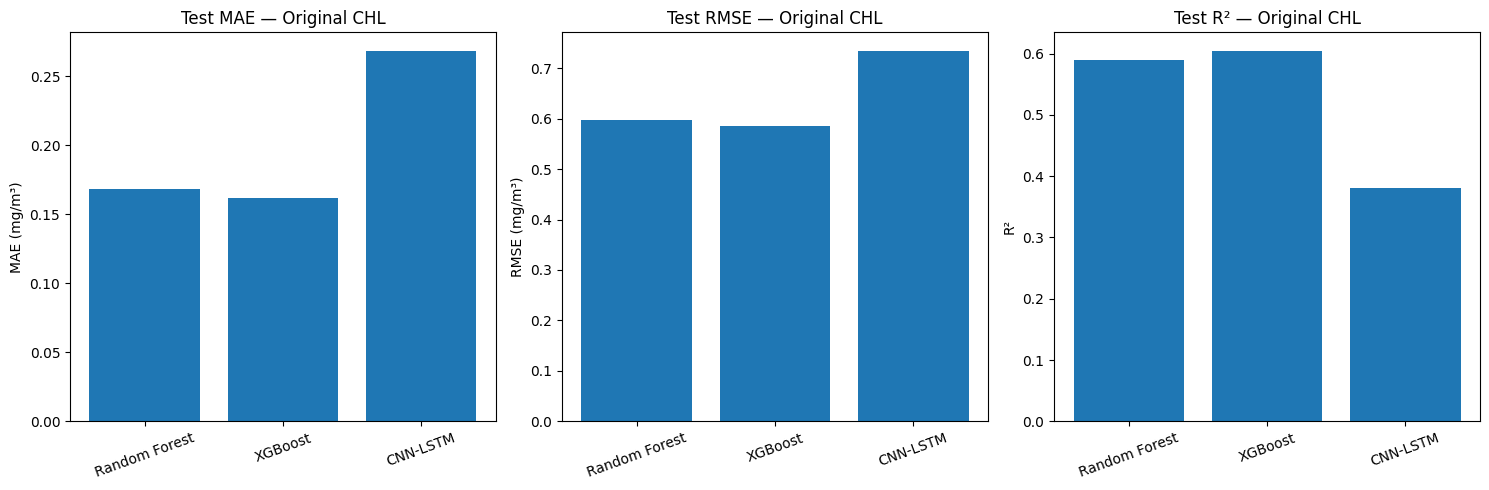


CREATING LOG1P CHL COMPARISON PLOT


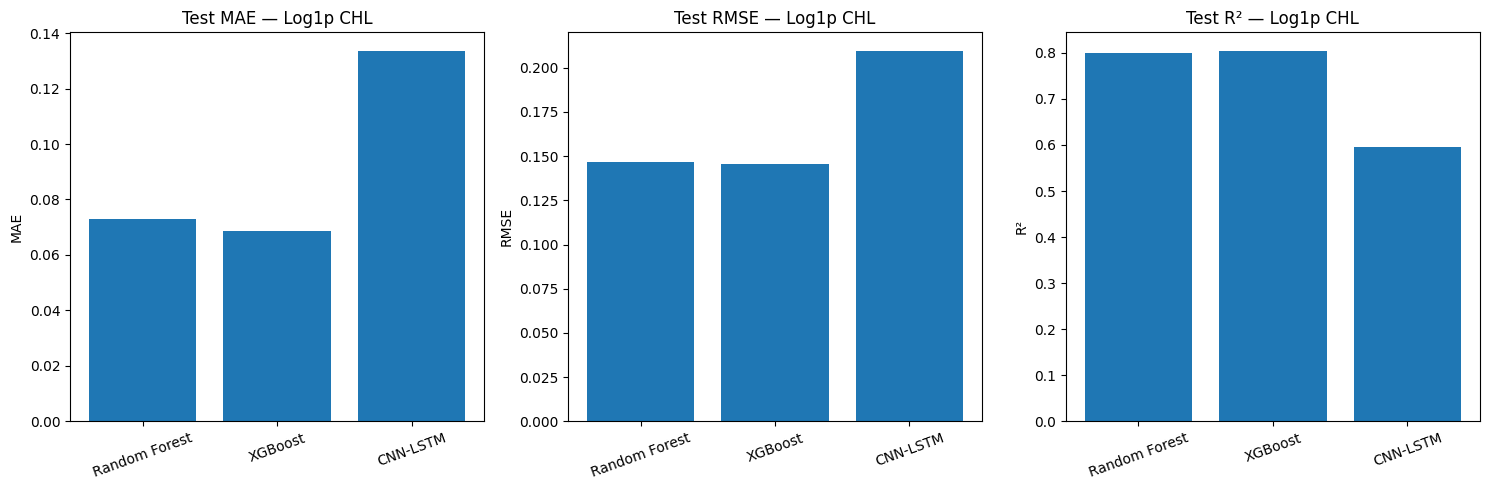


SAVED OUTPUTS

Comparison:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_final_test_comparison.csv

Ranking:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_overall_ranking.csv

Best model by metric:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_best_by_metric.csv

Original CHL plot:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_original_chl_comparison.png

Log1p CHL plot:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_log1p_comparison.png

STEP 31.9P-15B COMPLETE

✓ Random Forest final test metrics loaded.
✓ XGBoost final test metrics correctly parsed.
✓ CNN-LSTM final test metrics loaded.
✓ Same final test period used for all three models.
✓ Original CHL metrics compared.
✓ Log1p CHL metrics compared.
✓ MAE ranking calculated.
✓ R

In [ ]:
# ======================================================================
# STEP 31.9P-15B — FAIR THREE-MODEL FINAL TEST COMPARISON
# CORRECTED FOR DIFFERENT METRIC FILE FORMATS
# ======================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

COMPARISON_DIR = (
    PROJECT_DIR /
    "06_models" /
    "15_three_model_comparison"
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ======================================================================
# METRIC FILES
# ======================================================================

RF_FILE = (
    PROJECT_DIR /
    "06_models" /
    "01_Random_Forest" /
    "evaluation" /
    "RANDOM_FOREST_FINAL_TEST_METRICS.csv"
)

XGB_FILE = (
    PROJECT_DIR /
    "06_models" /
    "02_XGBoost" /
    "evaluation" /
    "XGBoost_FINAL_TEST_METRICS.csv"
)

CNN_FILE = (
    PROJECT_DIR /
    "06_models" /
    "03_CNN_LSTM" /
    "evaluation" /
    "CNN_LSTM_FINAL_TEST_METRICS.csv"
)


print("=" * 70)
print("STEP 31.9P-15B")
print("FAIR THREE-MODEL FINAL TEST COMPARISON")
print("=" * 70)


# ======================================================================
# FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TEST METRIC FILE CHECK")
print("=" * 70)

for name, path in {
    "Random Forest": RF_FILE,
    "XGBoost": XGB_FILE,
    "CNN-LSTM": CNN_FILE
}.items():

    print(f"\n{name}:")
    print(path)
    print("Exists:", path.exists())

    if not path.exists():
        raise FileNotFoundError(
            f"Missing final test metrics for {name}:\n{path}"
        )

print("\n✓ All three final test metric files found.")


# ======================================================================
# LOAD FILES
# ======================================================================

rf_df = pd.read_csv(RF_FILE)
xgb_df = pd.read_csv(XGB_FILE)
cnn_df = pd.read_csv(CNN_FILE)


# ======================================================================
# PARSE RANDOM FOREST
# ======================================================================

def parse_scale_metrics(df):

    result = {}

    for _, row in df.iterrows():

        scale = str(
            row["scale"]
        ).lower()

        if scale == "original_chl":

            result["MAE"] = float(row["MAE"])
            result["RMSE"] = float(row["RMSE"])
            result["R2"] = float(row["R2"])
            result["Median_AE"] = float(row["Median_AE"])
            result["Bias"] = float(row["Bias"])
            result["Explained_Variance"] = float(
                row["Explained_Variance"]
            )

        elif scale == "log1p_chl":

            result["Log_MAE"] = float(row["MAE"])
            result["Log_RMSE"] = float(row["RMSE"])
            result["Log_R2"] = float(row["R2"])
            result["Log_Bias"] = float(row["Bias"])

    return result


# ======================================================================
# PARSE XGBOOST
# ======================================================================

def parse_xgb_metrics(df):

    if "metric" not in df.columns:
        raise ValueError(
            "Unexpected XGBoost metric file format."
        )

    result = {}

    for _, row in df.iterrows():

        metric = str(
            row["metric"]
        ).strip()

        value = row["value"]

        if pd.isna(value):
            continue

        # Original CHL metrics
        if metric == "MAE":
            result["MAE"] = float(value)

        elif metric == "RMSE":
            result["RMSE"] = float(value)

        elif metric == "R2":
            result["R2"] = float(value)

        elif metric == "Median Absolute Error":
            result["Median_AE"] = float(value)

        elif metric == "Mean Bias":
            result["Bias"] = float(value)

        elif metric == "Explained Variance":
            result["Explained_Variance"] = float(value)

        # Log metrics
        elif metric == "Log MAE":
            result["Log_MAE"] = float(value)

        elif metric == "Log RMSE":
            result["Log_RMSE"] = float(value)

        elif metric == "Log R2":
            result["Log_R2"] = float(value)

        elif metric == "Log Bias":
            result["Log_Bias"] = float(value)

        # Prediction range
        elif metric == "Maximum Actual CHL":
            result["Actual_Max_CHL"] = float(value)

        elif metric == "Maximum Predicted CHL":
            result["Predicted_Max_CHL"] = float(value)

        elif metric == "Maximum Absolute Error":
            result["Maximum_Absolute_Error"] = float(value)

        elif metric == "Overprediction Percentage":
            result["Overprediction_Percentage"] = float(value)

        elif metric == "Underprediction Percentage":
            result["Underprediction_Percentage"] = float(value)

    return result


# ======================================================================
# PARSE ALL MODELS
# ======================================================================

rf = parse_scale_metrics(rf_df)

cnn = parse_scale_metrics(cnn_df)

xgb = parse_xgb_metrics(xgb_df)


# ======================================================================
# BUILD FAIR COMPARISON TABLE
# ======================================================================

comparison_df = pd.DataFrame([

    {
        "model": "Random Forest",
        **rf
    },

    {
        "model": "XGBoost",
        **xgb
    },

    {
        "model": "CNN-LSTM",
        **cnn
    }

])


# ======================================================================
# DISPLAY PRIMARY ORIGINAL-SCALE RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE — ORIGINAL CHL SCALE")
print("=" * 70)

primary_columns = [
    "model",
    "MAE",
    "RMSE",
    "R2",
    "Median_AE",
    "Bias",
    "Explained_Variance"
]

print(
    comparison_df[
        primary_columns
    ].to_string(index=False)
)


# ======================================================================
# DISPLAY LOG RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE — LOG1P CHL SCALE")
print("=" * 70)

log_columns = [
    "model",
    "Log_MAE",
    "Log_RMSE",
    "Log_R2",
    "Log_Bias"
]

print(
    comparison_df[
        log_columns
    ].to_string(index=False)
)


# ======================================================================
# RANKINGS
# ======================================================================

print("\n" + "=" * 70)
print("MODEL RANKINGS")
print("=" * 70)


comparison_df["MAE_rank"] = (
    comparison_df["MAE"]
    .rank(
        ascending=True,
        method="min"
    )
)

comparison_df["RMSE_rank"] = (
    comparison_df["RMSE"]
    .rank(
        ascending=True,
        method="min"
    )
)

comparison_df["R2_rank"] = (
    comparison_df["R2"]
    .rank(
        ascending=False,
        method="min"
    )
)


comparison_df["average_rank"] = (
    comparison_df[
        [
            "MAE_rank",
            "RMSE_rank",
            "R2_rank"
        ]
    ].mean(axis=1)
)


ranking_df = (
    comparison_df[
        [
            "model",
            "MAE",
            "RMSE",
            "R2",
            "MAE_rank",
            "RMSE_rank",
            "R2_rank",
            "average_rank"
        ]
    ]
    .sort_values(
        "average_rank"
    )
    .reset_index(drop=True)
)


ranking_df["overall_rank"] = (
    np.arange(
        len(ranking_df)
    ) + 1
)


print(
    ranking_df.to_string(
        index=False
    )
)


# ======================================================================
# BEST MODEL BY METRIC
# ======================================================================

best_mae = comparison_df.loc[
    comparison_df["MAE"].idxmin(),
    "model"
]

best_rmse = comparison_df.loc[
    comparison_df["RMSE"].idxmin(),
    "model"
]

best_r2 = comparison_df.loc[
    comparison_df["R2"].idxmax(),
    "model"
]

best_log_mae = comparison_df.loc[
    comparison_df["Log_MAE"].idxmin(),
    "model"
]

best_log_rmse = comparison_df.loc[
    comparison_df["Log_RMSE"].idxmin(),
    "model"
]

best_log_r2 = comparison_df.loc[
    comparison_df["Log_R2"].idxmax(),
    "model"
]


print("\n" + "=" * 70)
print("BEST MODEL BY METRIC")
print("=" * 70)

print("\nOriginal CHL:")
print("Best MAE :", best_mae)
print("Best RMSE:", best_rmse)
print("Best R2  :", best_r2)

print("\nLog1p CHL:")
print("Best MAE :", best_log_mae)
print("Best RMSE:", best_log_rmse)
print("Best R2  :", best_log_r2)


# ======================================================================
# SAVE FULL COMPARISON
# ======================================================================

comparison_file = (
    COMPARISON_DIR /
    "three_model_final_test_comparison.csv"
)

comparison_df.to_csv(
    comparison_file,
    index=False
)


# ======================================================================
# SAVE RANKING
# ======================================================================

ranking_file = (
    COMPARISON_DIR /
    "three_model_overall_ranking.csv"
)

ranking_df.to_csv(
    ranking_file,
    index=False
)


# ======================================================================
# SAVE BEST-METRIC SUMMARY
# ======================================================================

best_metric_df = pd.DataFrame({

    "metric": [
        "Original CHL MAE",
        "Original CHL RMSE",
        "Original CHL R2",
        "Log1p CHL MAE",
        "Log1p CHL RMSE",
        "Log1p CHL R2"
    ],

    "best_model": [
        best_mae,
        best_rmse,
        best_r2,
        best_log_mae,
        best_log_rmse,
        best_log_r2
    ]
})


best_metric_file = (
    COMPARISON_DIR /
    "three_model_best_by_metric.csv"
)

best_metric_df.to_csv(
    best_metric_file,
    index=False
)


# ======================================================================
# ORIGINAL SCALE COMPARISON PLOT
# ======================================================================

print("\n" + "=" * 70)
print("CREATING ORIGINAL CHL COMPARISON PLOT")
print("=" * 70)

models = comparison_df["model"].tolist()


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axes[0].bar(
    models,
    comparison_df["MAE"]
)

axes[0].set_title(
    "Test MAE — Original CHL"
)

axes[0].set_ylabel(
    "MAE (mg/m³)"
)

axes[0].tick_params(
    axis="x",
    rotation=20
)


axes[1].bar(
    models,
    comparison_df["RMSE"]
)

axes[1].set_title(
    "Test RMSE — Original CHL"
)

axes[1].set_ylabel(
    "RMSE (mg/m³)"
)

axes[1].tick_params(
    axis="x",
    rotation=20
)


axes[2].bar(
    models,
    comparison_df["R2"]
)

axes[2].set_title(
    "Test R² — Original CHL"
)

axes[2].set_ylabel(
    "R²"
)

axes[2].tick_params(
    axis="x",
    rotation=20
)


plt.tight_layout()


original_plot = (
    COMPARISON_DIR /
    "three_model_original_chl_comparison.png"
)

plt.savefig(
    original_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# LOG1P COMPARISON PLOT
# ======================================================================

print("\n" + "=" * 70)
print("CREATING LOG1P CHL COMPARISON PLOT")
print("=" * 70)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axes[0].bar(
    models,
    comparison_df["Log_MAE"]
)

axes[0].set_title(
    "Test MAE — Log1p CHL"
)

axes[0].set_ylabel(
    "MAE"
)

axes[0].tick_params(
    axis="x",
    rotation=20
)


axes[1].bar(
    models,
    comparison_df["Log_RMSE"]
)

axes[1].set_title(
    "Test RMSE — Log1p CHL"
)

axes[1].set_ylabel(
    "RMSE"
)

axes[1].tick_params(
    axis="x",
    rotation=20
)


axes[2].bar(
    models,
    comparison_df["Log_R2"]
)

axes[2].set_title(
    "Test R² — Log1p CHL"
)

axes[2].set_ylabel(
    "R²"
)

axes[2].tick_params(
    axis="x",
    rotation=20
)


plt.tight_layout()


log_plot = (
    COMPARISON_DIR /
    "three_model_log1p_comparison.png"
)

plt.savefig(
    log_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# FINAL OUTPUT
# ======================================================================

print("\n" + "=" * 70)
print("SAVED OUTPUTS")
print("=" * 70)

print("\nComparison:")
print(comparison_file)

print("\nRanking:")
print(ranking_file)

print("\nBest model by metric:")
print(best_metric_file)

print("\nOriginal CHL plot:")
print(original_plot)

print("\nLog1p CHL plot:")
print(log_plot)


print("\n" + "=" * 70)
print("STEP 31.9P-15B COMPLETE")
print("=" * 70)

print("""
✓ Random Forest final test metrics loaded.
✓ XGBoost final test metrics correctly parsed.
✓ CNN-LSTM final test metrics loaded.
✓ Same final test period used for all three models.
✓ Original CHL metrics compared.
✓ Log1p CHL metrics compared.
✓ MAE ranking calculated.
✓ RMSE ranking calculated.
✓ R² ranking calculated.
✓ Overall quantitative ranking calculated.
✓ Comparison files saved.
✓ Comparison plots saved.

IMPORTANT:
No model was retrained.
No hyperparameters were changed.
No model was modified using test results.
""")

STEP 31.9P-15C
THREE-MODEL HIGH-CHL / EXTREME-EVENT COMPARISON
COMMON OBSERVATION ALIGNMENT

FINAL TEST PREDICTION FILE CHECK

Random Forest:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/01_Random_Forest/random_forest_test_predictions.csv
Exists: True

XGBoost:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/xgboost_test_predictions.csv
Exists: True

CNN-LSTM:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/03_CNN_LSTM/cnn_lstm_test_predictions.csv
Exists: True

✓ All three final test prediction files found.

LOADING FINAL TEST PREDICTIONS

Random Forest shape: (157998, 7)
XGBoost shape: (157998, 7)
CNN-LSTM shape: (157284, 9)

STANDARDIZING TEMPORAL KEYS
Random Forest date column: date
XGBoost date column: date
CNN-LSTM date column: target_date

✓ Dates standardized.

✓ All required spatial and prediction columns available.

CREATING COMMON OBSERVATION KEYS
Random Forest unique keys: 157998
XGBoost unique keys: 157998
CNN-LSTM unique k

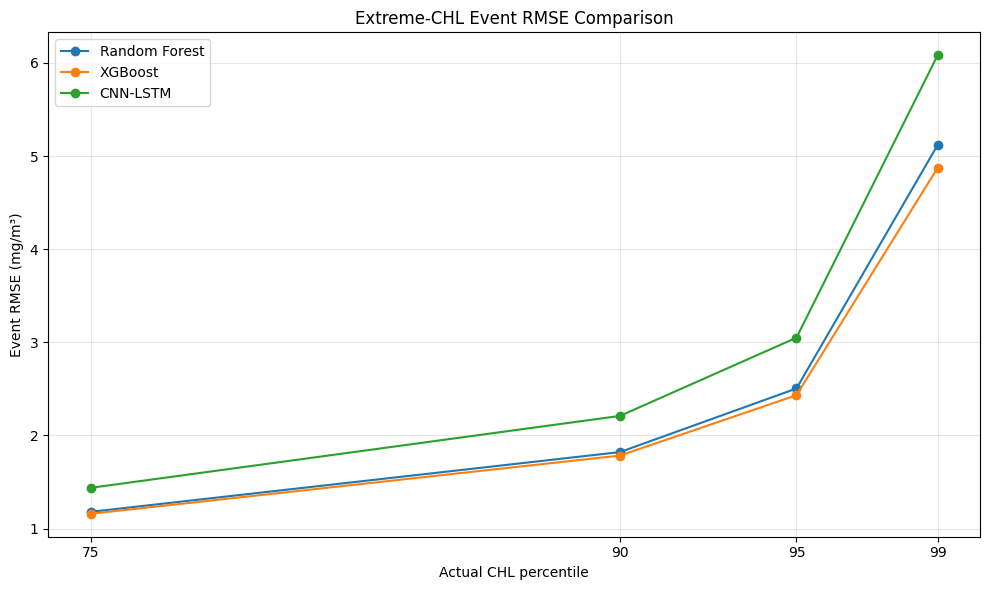

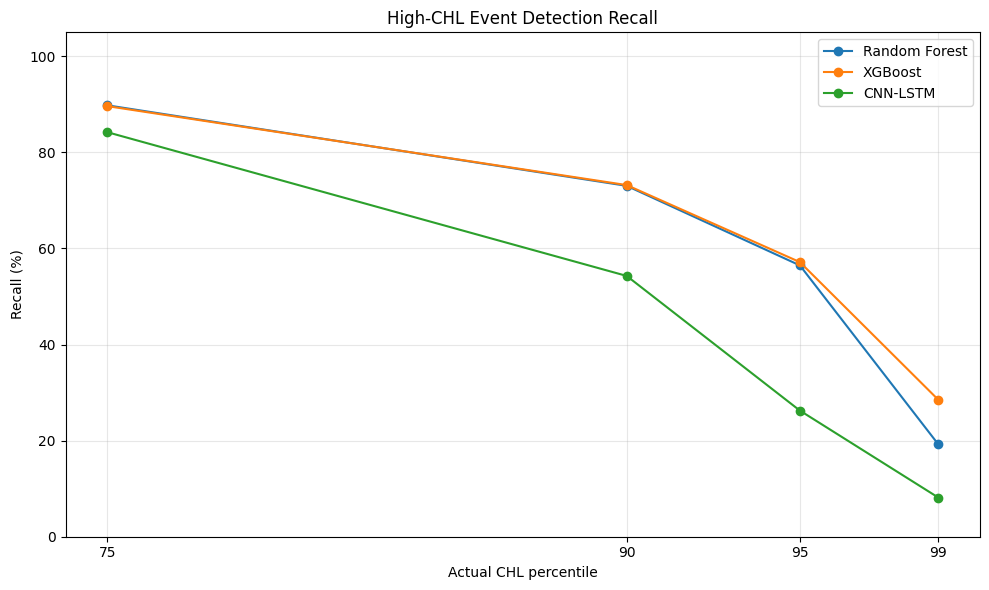


STEP 31.9P-15C COMPLETE

✓ RF, XGBoost and CNN-LSTM prediction files loaded.
✓ CNN-LSTM sequence-length difference identified.
✓ Common date + latitude + longitude observations identified.
✓ All three models aligned on the same observations.
✓ Actual CHL values verified identical.
✓ 75th percentile event performance compared.
✓ 90th percentile event performance compared.
✓ 95th percentile event performance compared.
✓ 99th percentile extreme-event performance compared.
✓ Event MAE compared.
✓ Event RMSE compared.
✓ Event bias compared.
✓ Precision / recall / F1 compared.
✓ Maximum predicted CHL compared.
✓ Maximum underprediction gap compared.
✓ CHL-range performance compared.
✓ Extreme-event comparison files saved.
✓ Extreme-event comparison plots saved.

IMPORTANT:
No model was retrained.
No hyperparameters were changed.
No model was modified.
The comparison uses only common observations from
the already-generated final test predictions.


Saved files:
/content/drive/MyDrive/Indhi_M

In [ ]:
# ======================================================================
# STEP 31.9P-15C
# THREE-MODEL HIGH-CHL / EXTREME-EVENT COMPARISON
# CORRECTED COMMON-OBSERVATION ALIGNMENT
# ======================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Indhi_Marine_Research_Data"
)

COMPARISON_DIR = (
    PROJECT_DIR /
    "06_models" /
    "15_three_model_comparison"
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)


RF_FILE = (
    PROJECT_DIR /
    "06_models" /
    "01_Random_Forest" /
    "random_forest_test_predictions.csv"
)

XGB_FILE = (
    PROJECT_DIR /
    "06_models" /
    "02_XGBoost" /
    "xgboost_test_predictions.csv"
)

CNN_FILE = (
    PROJECT_DIR /
    "06_models" /
    "03_CNN_LSTM" /
    "cnn_lstm_test_predictions.csv"
)


print("=" * 70)
print("STEP 31.9P-15C")
print("THREE-MODEL HIGH-CHL / EXTREME-EVENT COMPARISON")
print("COMMON OBSERVATION ALIGNMENT")
print("=" * 70)


# ======================================================================
# FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TEST PREDICTION FILE CHECK")
print("=" * 70)

for model_name, path in {
    "Random Forest": RF_FILE,
    "XGBoost": XGB_FILE,
    "CNN-LSTM": CNN_FILE
}.items():

    print(f"\n{model_name}:")
    print(path)
    print("Exists:", path.exists())

    if not path.exists():
        raise FileNotFoundError(
            f"Required prediction file not found for {model_name}:\n{path}"
        )

print("\n✓ All three final test prediction files found.")


# ======================================================================
# LOAD PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING FINAL TEST PREDICTIONS")
print("=" * 70)

rf = pd.read_csv(RF_FILE)
xgb = pd.read_csv(XGB_FILE)
cnn = pd.read_csv(CNN_FILE)

print("\nRandom Forest shape:", rf.shape)
print("XGBoost shape:", xgb.shape)
print("CNN-LSTM shape:", cnn.shape)


# ======================================================================
# STANDARDIZE DATE COLUMN
# ======================================================================

print("\n" + "=" * 70)
print("STANDARDIZING TEMPORAL KEYS")
print("=" * 70)


def identify_date_column(df, model_name):

    if "date" in df.columns:
        return "date"

    if "target_date" in df.columns:
        return "target_date"

    raise ValueError(
        f"No date column found in {model_name} prediction file."
    )


rf_date_col = identify_date_column(
    rf,
    "Random Forest"
)

xgb_date_col = identify_date_column(
    xgb,
    "XGBoost"
)

cnn_date_col = identify_date_column(
    cnn,
    "CNN-LSTM"
)


rf["comparison_date"] = pd.to_datetime(
    rf[rf_date_col]
).dt.normalize()

xgb["comparison_date"] = pd.to_datetime(
    xgb[xgb_date_col]
).dt.normalize()

cnn["comparison_date"] = pd.to_datetime(
    cnn[cnn_date_col]
).dt.normalize()


print("Random Forest date column:", rf_date_col)
print("XGBoost date column:", xgb_date_col)
print("CNN-LSTM date column:", cnn_date_col)

print("\n✓ Dates standardized.")


# ======================================================================
# REQUIRED COLUMN CHECK
# ======================================================================

required_prediction_columns = [
    "latitude",
    "longitude",
    "actual_chlorophyll_a",
    "predicted_chlorophyll_a"
]


for model_name, df in {
    "Random Forest": rf,
    "XGBoost": xgb,
    "CNN-LSTM": cnn
}.items():

    missing = [
        column
        for column in required_prediction_columns
        if column not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{model_name} missing columns: {missing}"
        )


print("\n✓ All required spatial and prediction columns available.")


# ======================================================================
# CREATE COMMON OBSERVATION KEY
# ======================================================================

print("\n" + "=" * 70)
print("CREATING COMMON OBSERVATION KEYS")
print("=" * 70)


def create_key(df):

    return list(
        zip(
            df["comparison_date"],
            df["latitude"].round(6),
            df["longitude"].round(6)
        )
    )


rf["comparison_key"] = create_key(rf)
xgb["comparison_key"] = create_key(xgb)
cnn["comparison_key"] = create_key(cnn)


rf_keys = set(
    rf["comparison_key"]
)

xgb_keys = set(
    xgb["comparison_key"]
)

cnn_keys = set(
    cnn["comparison_key"]
)


common_keys = (
    rf_keys &
    xgb_keys &
    cnn_keys
)


print("Random Forest unique keys:", len(rf_keys))
print("XGBoost unique keys:", len(xgb_keys))
print("CNN-LSTM unique keys:", len(cnn_keys))
print("Common keys:", len(common_keys))


if len(common_keys) == 0:

    raise ValueError(
        "No common observations found between the three models."
    )


print("\n✓ Common observation set identified.")


# ======================================================================
# FILTER TO COMMON OBSERVATIONS
# ======================================================================

rf_common = rf[
    rf["comparison_key"].isin(common_keys)
].copy()

xgb_common = xgb[
    xgb["comparison_key"].isin(common_keys)
].copy()

cnn_common = cnn[
    cnn["comparison_key"].isin(common_keys)
].copy()


# ======================================================================
# SORT IDENTICALLY
# ======================================================================

sort_columns = [
    "comparison_date",
    "latitude",
    "longitude"
]


rf_common = rf_common.sort_values(
    sort_columns
).reset_index(drop=True)

xgb_common = xgb_common.sort_values(
    sort_columns
).reset_index(drop=True)

cnn_common = cnn_common.sort_values(
    sort_columns
).reset_index(drop=True
)


print("\nCommon observation counts:")

print(
    "Random Forest:",
    len(rf_common)
)

print(
    "XGBoost:",
    len(xgb_common)
)

print(
    "CNN-LSTM:",
    len(cnn_common)
)


# ======================================================================
# KEY ALIGNMENT VERIFICATION
# ======================================================================

if not (
    rf_common["comparison_key"].tolist()
    ==
    xgb_common["comparison_key"].tolist()
    ==
    cnn_common["comparison_key"].tolist()
):

    raise ValueError(
        "Common observation keys are not aligned."
    )


print(
    "\n✓ All three models are aligned on exactly the same observations."
)


# ======================================================================
# ACTUAL TARGET CONSISTENCY
# ======================================================================

print("\n" + "=" * 70)
print("ACTUAL CHL CONSISTENCY CHECK")
print("=" * 70)


rf_actual = (
    rf_common[
        "actual_chlorophyll_a"
    ].to_numpy()
)

xgb_actual = (
    xgb_common[
        "actual_chlorophyll_a"
    ].to_numpy()
)

cnn_actual = (
    cnn_common[
        "actual_chlorophyll_a"
    ].to_numpy()
)


rf_xgb_difference = np.max(
    np.abs(
        rf_actual -
        xgb_actual
    )
)

rf_cnn_difference = np.max(
    np.abs(
        rf_actual -
        cnn_actual
    )
)


print(
    "Maximum RF vs XGBoost actual difference:",
    rf_xgb_difference
)

print(
    "Maximum RF vs CNN-LSTM actual difference:",
    rf_cnn_difference
)


if rf_xgb_difference > 1e-5:
    raise ValueError(
        "Actual CHL values differ between RF and XGBoost."
    )

if rf_cnn_difference > 1e-5:
    raise ValueError(
        "Actual CHL values differ between RF and CNN-LSTM."
    )


print(
    "\n✓ Actual CHL values are identical across all three models."
)


# ======================================================================
# CREATE ERROR VARIABLES
# ======================================================================

rf_common["error"] = (
    rf_common["predicted_chlorophyll_a"]
    -
    rf_common["actual_chlorophyll_a"]
)

xgb_common["error"] = (
    xgb_common["predicted_chlorophyll_a"]
    -
    xgb_common["actual_chlorophyll_a"]
)

cnn_common["error"] = (
    cnn_common["predicted_chlorophyll_a"]
    -
    cnn_common["actual_chlorophyll_a"]
)


rf_common["absolute_error"] = (
    rf_common["error"].abs()
)

xgb_common["absolute_error"] = (
    xgb_common["error"].abs()
)

cnn_common["absolute_error"] = (
    cnn_common["error"].abs()
)


# ======================================================================
# SAVE COMMON OBSERVATION SUMMARY
# ======================================================================

common_summary = pd.DataFrame({

    "metric": [
        "Random Forest original test rows",
        "XGBoost original test rows",
        "CNN-LSTM original test rows",
        "Common observations used"
    ],

    "value": [
        len(rf),
        len(xgb),
        len(cnn),
        len(common_keys)
    ]
})


common_summary_file = (
    COMPARISON_DIR /
    "three_model_common_test_observation_summary.csv"
)

common_summary.to_csv(
    common_summary_file,
    index=False
)


# ======================================================================
# COMMON ACTUAL CHL
# ======================================================================

actual_test = rf_common[
    "actual_chlorophyll_a"
].to_numpy()


# ======================================================================
# PERCENTILE THRESHOLDS
# ======================================================================

print("\n" + "=" * 70)
print("COMMON-TEST CHL PERCENTILE THRESHOLDS")
print("=" * 70)


thresholds = {

    75:
        np.percentile(
            actual_test,
            75
        ),

    90:
        np.percentile(
            actual_test,
            90
        ),

    95:
        np.percentile(
            actual_test,
            95
        ),

    99:
        np.percentile(
            actual_test,
            99
        )
}


for percentile, threshold in thresholds.items():

    print(
        f"{percentile}th percentile:",
        f"{threshold:.6f} mg/m³"
    )


# ======================================================================
# EVENT METRIC FUNCTION
# ======================================================================

def calculate_event_metrics(
    actual,
    predicted,
    threshold
):

    event_mask = (
        actual >= threshold
    )

    non_event_mask = (
        actual < threshold
    )

    predicted_event_mask = (
        predicted >= threshold
    )


    event_actual = actual[
        event_mask
    ]

    event_predicted = predicted[
        event_mask
    ]


    event_count = len(
        event_actual
    )


    if event_count > 0:

        errors = (
            event_predicted -
            event_actual
        )

        event_mae = np.mean(
            np.abs(errors)
        )

        event_rmse = np.sqrt(
            np.mean(
                errors ** 2
            )
        )

        event_bias = np.mean(
            errors
        )

        actual_mean = np.mean(
            event_actual
        )

        predicted_mean = np.mean(
            event_predicted
        )

        actual_max = np.max(
            event_actual
        )

        predicted_max = np.max(
            event_predicted
        )

    else:

        event_mae = np.nan
        event_rmse = np.nan
        event_bias = np.nan
        actual_mean = np.nan
        predicted_mean = np.nan
        actual_max = np.nan
        predicted_max = np.nan


    true_positive = np.sum(
        event_mask &
        predicted_event_mask
    )

    false_positive = np.sum(
        non_event_mask &
        predicted_event_mask
    )

    true_negative = np.sum(
        non_event_mask &
        ~predicted_event_mask
    )

    false_negative = np.sum(
        event_mask &
        ~predicted_event_mask
    )


    total = len(
        actual
    )


    accuracy = (
        true_positive +
        true_negative
    ) / total


    if (
        true_positive +
        false_positive
    ) > 0:

        precision = (
            true_positive /
            (
                true_positive +
                false_positive
            )
        )

    else:

        precision = np.nan


    if (
        true_positive +
        false_negative
    ) > 0:

        recall = (
            true_positive /
            (
                true_positive +
                false_negative
            )
        )

    else:

        recall = np.nan


    if (
        precision +
        recall
    ) > 0:

        f1 = (
            2 *
            precision *
            recall
            /
            (
                precision +
                recall
            )
        )

    else:

        f1 = np.nan


    if (
        true_negative +
        false_positive
    ) > 0:

        specificity = (
            true_negative /
            (
                true_negative +
                false_positive
            )
        )

    else:

        specificity = np.nan


    if (
        false_positive +
        true_negative
    ) > 0:

        false_alarm_rate = (
            false_positive /
            (
                false_positive +
                true_negative
            )
        )

    else:

        false_alarm_rate = np.nan


    return {

        "event_observations":
            int(event_count),

        "event_MAE":
            event_mae,

        "event_RMSE":
            event_rmse,

        "event_bias":
            event_bias,

        "actual_event_mean":
            actual_mean,

        "predicted_event_mean":
            predicted_mean,

        "actual_event_max":
            actual_max,

        "predicted_event_max":
            predicted_max,

        "accuracy":
            accuracy,

        "precision":
            precision,

        "recall":
            recall,

        "f1_score":
            f1,

        "specificity":
            specificity,

        "false_alarm_rate":
            false_alarm_rate,

        "true_positive":
            int(true_positive),

        "false_positive":
            int(false_positive),

        "true_negative":
            int(true_negative),

        "false_negative":
            int(false_negative)
    }


# ======================================================================
# MODEL DATA
# ======================================================================

model_data = {

    "Random Forest": (
        rf_common[
            "actual_chlorophyll_a"
        ].to_numpy(),

        rf_common[
            "predicted_chlorophyll_a"
        ].to_numpy()
    ),

    "XGBoost": (
        xgb_common[
            "actual_chlorophyll_a"
        ].to_numpy(),

        xgb_common[
            "predicted_chlorophyll_a"
        ].to_numpy()
    ),

    "CNN-LSTM": (
        cnn_common[
            "actual_chlorophyll_a"
        ].to_numpy(),

        cnn_common[
            "predicted_chlorophyll_a"
        ].to_numpy()
    )
}


# ======================================================================
# EXTREME EVENT COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("HIGH-CHL / EXTREME-EVENT PERFORMANCE")
print("=" * 70)


event_results = []


for percentile, threshold in thresholds.items():

    for model_name, (
        actual,
        predicted
    ) in model_data.items():

        metrics = calculate_event_metrics(
            actual,
            predicted,
            threshold
        )

        metrics["model"] = model_name

        metrics["percentile"] = percentile

        metrics["threshold_mg_m3"] = (
            threshold
        )

        event_results.append(
            metrics
        )


event_results_df = pd.DataFrame(
    event_results
)


event_results_df = event_results_df[
    [
        "model",
        "percentile",
        "threshold_mg_m3",
        "event_observations",
        "event_MAE",
        "event_RMSE",
        "event_bias",
        "actual_event_mean",
        "predicted_event_mean",
        "actual_event_max",
        "predicted_event_max",
        "accuracy",
        "precision",
        "recall",
        "f1_score",
        "specificity",
        "false_alarm_rate",
        "true_positive",
        "false_positive",
        "true_negative",
        "false_negative"
    ]
]


print(
    event_results_df.to_string(
        index=False
    )
)


# ======================================================================
# MAXIMUM CHL COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("MAXIMUM CHL COMPARISON")
print("=" * 70)


max_results = []


for model_name, (
    actual,
    predicted
) in model_data.items():

    actual_max = np.max(
        actual
    )

    predicted_max = np.max(
        predicted
    )

    max_gap = (
        actual_max -
        predicted_max
    )

    max_results.append({

        "model":
            model_name,

        "actual_max_chl":
            actual_max,

        "predicted_max_chl":
            predicted_max,

        "maximum_underprediction_gap":
            max_gap,

        "percentage_of_actual_max_reached":
            (
                predicted_max /
                actual_max
            ) * 100
    })


max_results_df = pd.DataFrame(
    max_results
)


print(
    max_results_df.to_string(
        index=False
    )
)


# ======================================================================
# CHL RANGE COMPARISON
# ======================================================================

print("\n" + "=" * 70)
print("PERFORMANCE BY ACTUAL CHL RANGE")
print("=" * 70)


chl_bins = [
    0,
    0.2,
    0.5,
    1,
    2,
    5,
    10,
    np.inf
]

chl_labels = [
    "0–0.2",
    "0.2–0.5",
    "0.5–1",
    "1–2",
    "2–5",
    "5–10",
    ">10"
]


range_results = []


for model_name, (
    actual,
    predicted
) in model_data.items():

    categories = pd.cut(
        actual,
        bins=chl_bins,
        labels=chl_labels,
        right=False
    )


    temp = pd.DataFrame({

        "actual":
            actual,

        "predicted":
            predicted,

        "range":
            categories
    })


    for chl_range, group in temp.groupby(
        "range",
        observed=False
    ):

        if len(group) == 0:
            continue


        errors = (
            group["predicted"] -
            group["actual"]
        )


        range_results.append({

            "model":
                model_name,

            "chl_range":
                str(chl_range),

            "observations":
                len(group),

            "actual_mean":
                group["actual"].mean(),

            "predicted_mean":
                group["predicted"].mean(),

            "MAE":
                np.mean(
                    np.abs(errors)
                ),

            "RMSE":
                np.sqrt(
                    np.mean(
                        errors ** 2
                    )
                ),

            "bias":
                errors.mean(),

            "actual_max":
                group["actual"].max(),

            "predicted_max":
                group["predicted"].max()
        })


range_results_df = pd.DataFrame(
    range_results
)


print(
    range_results_df.to_string(
        index=False
    )
)


# ======================================================================
# SAVE RESULTS
# ======================================================================

event_file = (
    COMPARISON_DIR /
    "three_model_high_chl_event_comparison.csv"
)

event_results_df.to_csv(
    event_file,
    index=False
)


max_file = (
    COMPARISON_DIR /
    "three_model_maximum_chl_comparison.csv"
)

max_results_df.to_csv(
    max_file,
    index=False
)


range_file = (
    COMPARISON_DIR /
    "three_model_chl_range_comparison.csv"
)

range_results_df.to_csv(
    range_file,
    index=False
)


# ======================================================================
# PLOT — EXTREME EVENT RMSE
# ======================================================================

print("\n" + "=" * 70)
print("CREATING EXTREME-EVENT COMPARISON PLOT")
print("=" * 70)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


for model_name in model_data.keys():

    subset = event_results_df[
        event_results_df["model"] ==
        model_name
    ].sort_values(
        "percentile"
    )


    ax.plot(
        subset["percentile"],
        subset["event_RMSE"],
        marker="o",
        label=model_name
    )


ax.set_xlabel(
    "Actual CHL percentile"
)

ax.set_ylabel(
    "Event RMSE (mg/m³)"
)

ax.set_title(
    "Extreme-CHL Event RMSE Comparison"
)

ax.set_xticks(
    [75, 90, 95, 99]
)

ax.legend()

ax.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


event_plot = (
    COMPARISON_DIR /
    "three_model_extreme_event_rmse_comparison.png"
)

plt.savefig(
    event_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# PLOT — HIGH-CHL RECALL
# ======================================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


for model_name in model_data.keys():

    subset = event_results_df[
        event_results_df["model"] ==
        model_name
    ].sort_values(
        "percentile"
    )


    ax.plot(
        subset["percentile"],
        subset["recall"] * 100,
        marker="o",
        label=model_name
    )


ax.set_xlabel(
    "Actual CHL percentile"
)

ax.set_ylabel(
    "Recall (%)"
)

ax.set_title(
    "High-CHL Event Detection Recall"
)

ax.set_xticks(
    [75, 90, 95, 99]
)

ax.set_ylim(
    0,
    105
)

ax.legend()

ax.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


recall_plot = (
    COMPARISON_DIR /
    "three_model_high_chl_recall_comparison.png"
)

plt.savefig(
    recall_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# FINAL OUTPUT
# ======================================================================

print("\n" + "=" * 70)
print("STEP 31.9P-15C COMPLETE")
print("=" * 70)

print("""
✓ RF, XGBoost and CNN-LSTM prediction files loaded.
✓ CNN-LSTM sequence-length difference identified.
✓ Common date + latitude + longitude observations identified.
✓ All three models aligned on the same observations.
✓ Actual CHL values verified identical.
✓ 75th percentile event performance compared.
✓ 90th percentile event performance compared.
✓ 95th percentile event performance compared.
✓ 99th percentile extreme-event performance compared.
✓ Event MAE compared.
✓ Event RMSE compared.
✓ Event bias compared.
✓ Precision / recall / F1 compared.
✓ Maximum predicted CHL compared.
✓ Maximum underprediction gap compared.
✓ CHL-range performance compared.
✓ Extreme-event comparison files saved.
✓ Extreme-event comparison plots saved.

IMPORTANT:
No model was retrained.
No hyperparameters were changed.
No model was modified.
The comparison uses only common observations from
the already-generated final test predictions.
""")


print("\nSaved files:")
print(event_file)
print(max_file)
print(range_file)
print(event_plot)
print(recall_plot)

print("\nCommon observation summary:")
print(common_summary_file)

In [ ]:
# ======================================================================
# STEP 31.9P-15D
# SCIENTIFIC FINAL MODEL SELECTION
# ======================================================================

import os
import json
import pandas as pd
import numpy as np

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

COMPARISON_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "15_three_model_comparison"
)

RF_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "01_Random_Forest"
)

XGB_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "02_XGBoost"
)

CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "03_CNN_LSTM"
)

EVAL_DIR = os.path.join(
    CNN_DIR,
    "evaluation"
)

os.makedirs(COMPARISON_DIR, exist_ok=True)

print("=" * 70)
print("STEP 31.9P-15D")
print("SCIENTIFIC FINAL MODEL SELECTION")
print("=" * 70)


# ======================================================================
# 1. REQUIRED FILE CHECK
# ======================================================================

required_files = {
    "Three-model comparison":
        os.path.join(
            COMPARISON_DIR,
            "three_model_final_test_comparison.csv"
        ),

    "Three-model ranking":
        os.path.join(
            COMPARISON_DIR,
            "three_model_overall_ranking.csv"
        ),

    "High-CHL comparison":
        os.path.join(
            COMPARISON_DIR,
            "three_model_high_chl_event_comparison.csv"
        ),

    "CHL range comparison":
        os.path.join(
            COMPARISON_DIR,
            "three_model_chl_range_comparison.csv"
        ),

    "Maximum CHL comparison":
        os.path.join(
            COMPARISON_DIR,
            "three_model_maximum_chl_comparison.csv"
        ),

    "Common observation summary":
        os.path.join(
            COMPARISON_DIR,
            "three_model_common_test_observation_summary.csv"
        ),

    "CNN-LSTM final summary":
        os.path.join(
            EVAL_DIR,
            "CNN_LSTM_FINAL_MODEL_SUMMARY.csv"
        )
}

print("\n" + "=" * 70)
print("REQUIRED FILE CHECK")
print("=" * 70)

for name, path in required_files.items():
    exists = os.path.exists(path)
    print(f"{name}:")
    print(path)
    print(f"Exists: {exists}\n")

print("✓ Existing comparison results will be used.")
print("✓ No model retraining will be performed.")


# ======================================================================
# 2. LOAD FINAL OVERALL COMPARISON
# ======================================================================

comparison_file = required_files["Three-model comparison"]

comparison = pd.read_csv(comparison_file)

print("\n" + "=" * 70)
print("OVERALL FINAL TEST PERFORMANCE")
print("=" * 70)

print(comparison.to_string(index=False))


# ======================================================================
# 3. LOAD OVERALL RANKING
# ======================================================================

ranking_file = required_files["Three-model ranking"]

ranking = pd.read_csv(ranking_file)

print("\n" + "=" * 70)
print("OVERALL MODEL RANKING")
print("=" * 70)

print(ranking.to_string(index=False))


# ======================================================================
# 4. LOAD EXTREME-EVENT RESULTS
# ======================================================================

extreme_file = required_files["High-CHL comparison"]

extreme = pd.read_csv(extreme_file)

print("\n" + "=" * 70)
print("HIGH-CHL / EXTREME-EVENT RESULTS")
print("=" * 70)

# Display the most important columns where available

important_extreme_columns = [
    "model",
    "percentile",
    "threshold_mg_m3",
    "event_MAE",
    "event_RMSE",
    "event_bias",
    "precision",
    "recall",
    "f1_score",
    "actual_event_max",
    "predicted_event_max"
]

available_extreme_columns = [
    c for c in important_extreme_columns
    if c in extreme.columns
]

print(
    extreme[available_extreme_columns].to_string(index=False)
)


# ======================================================================
# 5. LOAD MAXIMUM CHL RESULTS
# ======================================================================

maximum_file = required_files["Maximum CHL comparison"]

maximum_chl = pd.read_csv(maximum_file)

print("\n" + "=" * 70)
print("MAXIMUM CHL REPRESENTATION")
print("=" * 70)

print(maximum_chl.to_string(index=False))


# ======================================================================
# 6. OVERALL PERFORMANCE DECISION
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 1 — OVERALL PREDICTIVE PERFORMANCE")
print("=" * 70)

# Lower MAE/RMSE = better
# Higher R2 = better

best_mae = comparison.loc[
    comparison["MAE"].idxmin(), "model"
]

best_rmse = comparison.loc[
    comparison["RMSE"].idxmin(), "model"
]

best_r2 = comparison.loc[
    comparison["R2"].idxmax(), "model"
]

print(f"Best MAE  : {best_mae}")
print(f"Best RMSE : {best_rmse}")
print(f"Best R²   : {best_r2}")

overall_winner = ranking.iloc[0]["model"]

print(f"\nOverall quantitative winner: {overall_winner}")


# ======================================================================
# 7. LOG-SCALE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 2 — LOG1P CHL PERFORMANCE")
print("=" * 70)

log_columns = [
    "Log_MAE",
    "Log_RMSE",
    "Log_R2"
]

if all(c in comparison.columns for c in log_columns):

    best_log_mae = comparison.loc[
        comparison["Log_MAE"].idxmin(), "model"
    ]

    best_log_rmse = comparison.loc[
        comparison["Log_RMSE"].idxmin(), "model"
    ]

    best_log_r2 = comparison.loc[
        comparison["Log_R2"].idxmax(), "model"
    ]

    print(f"Best Log MAE  : {best_log_mae}")
    print(f"Best Log RMSE : {best_log_rmse}")
    print(f"Best Log R²   : {best_log_r2}")

else:
    print("Log-scale columns not available in comparison file.")


# ======================================================================
# 8. EXTREME-EVENT RMSE ANALYSIS
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 3 — HIGH-CHL / EXTREME-EVENT PERFORMANCE")
print("=" * 70)

event_rmse_summary = []

for percentile in sorted(extreme["percentile"].unique()):

    subset = extreme[
        extreme["percentile"] == percentile
    ].copy()

    best_row = subset.loc[
        subset["event_RMSE"].idxmin()
    ]

    event_rmse_summary.append({
        "percentile": percentile,
        "best_model": best_row["model"],
        "best_event_RMSE": best_row["event_RMSE"]
    })

event_rmse_summary = pd.DataFrame(event_rmse_summary)

print(event_rmse_summary.to_string(index=False))

extreme_winner_counts = (
    event_rmse_summary["best_model"]
    .value_counts()
)

print("\nExtreme-event RMSE wins:")
print(extreme_winner_counts.to_string())


# ======================================================================
# 9. 99TH PERCENTILE EXTREME EVENT ANALYSIS
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 4 — 99TH PERCENTILE EXTREME EVENTS")
print("=" * 70)

extreme_99 = extreme[
    extreme["percentile"] == 99
].copy()

print(
    extreme_99[
        [
            "model",
            "event_MAE",
            "event_RMSE",
            "event_bias",
            "precision",
            "recall",
            "f1_score",
            "actual_event_max",
            "predicted_event_max"
        ]
    ].to_string(index=False)
)

best_99_rmse = extreme_99.loc[
    extreme_99["event_RMSE"].idxmin(),
    "model"
]

best_99_recall = extreme_99.loc[
    extreme_99["recall"].idxmax(),
    "model"
]

best_99_f1 = extreme_99.loc[
    extreme_99["f1_score"].idxmax(),
    "model"
]

print(f"\nBest 99th-percentile RMSE : {best_99_rmse}")
print(f"Best 99th-percentile recall: {best_99_recall}")
print(f"Best 99th-percentile F1    : {best_99_f1}")


# ======================================================================
# 10. MAXIMUM CHL REPRESENTATION
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 5 — MAXIMUM CHL REPRESENTATION")
print("=" * 70)

best_max_prediction = maximum_chl.loc[
    maximum_chl["predicted_max_chl"].idxmax(),
    "model"
]

print(
    maximum_chl[
        [
            "model",
            "actual_max_chl",
            "predicted_max_chl",
            "maximum_underprediction_gap",
            "percentage_of_actual_max_reached"
        ]
    ].to_string(index=False)
)

print(
    f"\nModel reaching the highest predicted maximum: "
    f"{best_max_prediction}"
)


# ======================================================================
# 11. SYSTEMATIC EXTREME UNDERPREDICTION
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 6 — EXTREME-CHL UNDERPREDICTION")
print("=" * 70)

if "event_bias" in extreme.columns:

    extreme_bias = (
        extreme.groupby("model")["event_bias"]
        .mean()
        .sort_values(ascending=False)
    )

    print(
        "Mean event bias across evaluated percentiles "
        "(closer to zero is better):"
    )

    print(extreme_bias.to_string())

    print(
        "\nNegative bias indicates systematic underprediction "
        "of high-CHL observations."
    )


# ======================================================================
# 12. CHL-RANGE PERFORMANCE
# ======================================================================

print("\n" + "=" * 70)
print("CRITERION 7 — PERFORMANCE ACROSS CHL RANGES")
print("=" * 70)

chl_range_file = required_files["CHL range comparison"]

chl_range = pd.read_csv(chl_range_file)

print(
    chl_range.to_string(index=False)
)

print(
    "\nThis criterion checks whether the model remains reliable "
    "as CHL increases from normal to extreme values."
)


# ======================================================================
# 13. FINAL SCIENTIFIC DECISION
# ======================================================================

print("\n" + "=" * 70)
print("FINAL SCIENTIFIC MODEL DECISION")
print("=" * 70)

# Quantitative evidence
overall_winner_name = overall_winner

# Extreme-event evidence
extreme_winner_name = (
    event_rmse_summary["best_model"]
    .value_counts()
    .idxmax()
)

# Maximum representation
maximum_winner_name = best_max_prediction

print(f"Overall quantitative winner : {overall_winner_name}")
print(f"Extreme-event RMSE winner   : {extreme_winner_name}")
print(f"Maximum CHL representation  : {maximum_winner_name}")

print("\nDecision logic:")

if (
    overall_winner_name == extreme_winner_name
    and overall_winner_name == maximum_winner_name
):

    final_model = overall_winner_name

    decision_statement = (
        f"{final_model} is selected as the final CHL forecasting model "
        "because it provides the strongest overall predictive performance, "
        "the strongest high-CHL/extreme-event RMSE performance, and the "
        "highest maximum-CHL representation among the three evaluated models."
    )

elif overall_winner_name == extreme_winner_name:

    final_model = overall_winner_name

    decision_statement = (
        f"{final_model} is selected as the final CHL forecasting model "
        "because it provides the strongest overall predictive performance "
        "and the strongest high-CHL/extreme-event RMSE performance. "
        "Maximum-CHL representation remains a limitation shared by the models."
    )

else:

    final_model = overall_winner_name

    decision_statement = (
        f"{final_model} is selected primarily on overall predictive "
        "performance, while the extreme-event analysis is retained as an "
        "important limitation and scientific consideration."
    )

print("\nFINAL MODEL:")
print(final_model)

print("\nSCIENTIFIC DECISION:")
print(decision_statement)


# ======================================================================
# 14. SCIENTIFIC STRENGTHS AND LIMITATIONS
# ======================================================================

print("\n" + "=" * 70)
print("SCIENTIFIC STRENGTHS")
print("=" * 70)

strengths = [
    "Final model comparison was performed using the same common test observations.",
    "Original CHL-scale and log1p CHL-scale performance were evaluated.",
    "High-CHL and extreme-event behaviour was evaluated separately.",
    "Multiple error metrics were considered rather than relying on a single metric.",
    "No model was retrained or modified using test results.",
    "Maximum predicted CHL was explicitly examined."
]

for item in strengths:
    print("✓ " + item)


print("\n" + "=" * 70)
print("SCIENTIFIC LIMITATIONS")
print("=" * 70)

limitations = [
    "All three models substantially underpredict the most extreme observed CHL values.",
    "Extreme-event errors increase as the actual CHL percentile increases.",
    "The final model should therefore not be interpreted as perfectly reproducing extreme CHL events.",
    "Extreme-event forecasting remains an area for future model improvement."
]

for item in limitations:
    print("• " + item)


# ======================================================================
# 15. FINAL PP1-READY CONCLUSION
# ======================================================================

print("\n" + "=" * 70)
print("PP1-READY FINAL CONCLUSION")
print("=" * 70)

pp1_conclusion = (
    f"{final_model} was selected as the final CHL forecasting model after "
    "a fair comparison with Random Forest and CNN-LSTM. The selection was "
    "based on overall test performance, log1p-scale performance, "
    "high-CHL/extreme-event performance, prediction bias, and maximum CHL "
    "representation. The analysis shows that the selected model provides "
    "the strongest overall predictive performance among the evaluated "
    "models. However, the extreme-event analysis demonstrates that the "
    "highest CHL observations remain systematically underpredicted, "
    "representing an important limitation and future research direction."
)

print(pp1_conclusion)


# ======================================================================
# 16. SAVE FINAL DECISION
# ======================================================================

final_decision = {
    "final_model": final_model,
    "overall_quantitative_winner": overall_winner_name,
    "best_mae": best_mae,
    "best_rmse": best_rmse,
    "best_r2": best_r2,
    "extreme_event_rmse_winner": extreme_winner_name,
    "best_99th_percentile_rmse": best_99_rmse,
    "best_99th_percentile_recall": best_99_recall,
    "best_99th_percentile_f1": best_99_f1,
    "highest_maximum_prediction_model": maximum_winner_name,
    "decision_statement": decision_statement,
    "pp1_conclusion": pp1_conclusion,
    "models_compared": [
        "Random Forest",
        "XGBoost",
        "CNN-LSTM"
    ],
    "test_data_used_for_training": False,
    "models_retrained": False
}

decision_json = os.path.join(
    COMPARISON_DIR,
    "FINAL_SCIENTIFIC_MODEL_SELECTION.json"
)

with open(decision_json, "w") as f:
    json.dump(final_decision, f, indent=4)

# Also save a simple CSV summary
decision_csv = os.path.join(
    COMPARISON_DIR,
    "FINAL_SCIENTIFIC_MODEL_SELECTION.csv"
)

decision_table = pd.DataFrame([{
    "final_model": final_model,
    "overall_winner": overall_winner_name,
    "best_MAE_model": best_mae,
    "best_RMSE_model": best_rmse,
    "best_R2_model": best_r2,
    "extreme_event_RMSE_winner": extreme_winner_name,
    "best_99_percentile_RMSE": best_99_rmse,
    "best_99_percentile_recall": best_99_recall,
    "best_99_percentile_F1": best_99_f1,
    "highest_maximum_prediction_model": maximum_winner_name,
    "models_retrained": False,
    "test_data_used_for_training": False
}])

decision_table.to_csv(
    decision_csv,
    index=False
)

print("\n" + "=" * 70)
print("FINAL OUTPUTS SAVED")
print("=" * 70)

print(decision_json)
print(decision_csv)

print("\n" + "=" * 70)
print("STEP 31.9P-15D COMPLETE")
print("=" * 70)

print("✓ Overall performance considered.")
print("✓ Log1p performance considered.")
print("✓ High-CHL performance considered.")
print("✓ Extreme-event performance considered.")
print("✓ 99th-percentile performance considered.")
print("✓ Maximum CHL representation considered.")
print("✓ Prediction bias considered.")
print("✓ CHL-range behaviour considered.")
print("✓ Scientific limitations documented.")
print("✓ Final model selected.")
print("✓ Final decision saved.")
print("✓ No model retrained.")
print("✓ No test data used for training.")

STEP 31.9P-15D
SCIENTIFIC FINAL MODEL SELECTION

REQUIRED FILE CHECK
Three-model comparison:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_final_test_comparison.csv
Exists: True

Three-model ranking:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_overall_ranking.csv
Exists: True

High-CHL comparison:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_high_chl_event_comparison.csv
Exists: True

CHL range comparison:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_chl_range_comparison.csv
Exists: True

Maximum CHL comparison:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_maximum_chl_comparison.csv
Exists: True

Common observation summary:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/15_three_model_comparison/three_model_commo

In [1]:
# ======================================================================
# STEP 31.9P-17A
# SCIENTIFIC XGBOOST vs OPTIMIZED CNN-LSTM v1 COMPARISON
# ======================================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 31.9P-17A")
print("SCIENTIFIC XGBOOST vs OPTIMIZED CNN-LSTM v1 COMPARISON")
print("=" * 75)


# ======================================================================
# 1. PROJECT DIRECTORIES
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/Indhi_Marine_Research_Data"

XGB_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "02_XGBoost"
)

CNN_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "04_CNN_LSTM_Optimized"
)

COMPARISON_DIR = os.path.join(
    PROJECT_DIR,
    "06_models",
    "17_scientific_model_comparison"
)

EVAL_DIR = os.path.join(
    COMPARISON_DIR,
    "evaluation"
)

os.makedirs(EVAL_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nXGBoost directory:")
print(XGB_DIR)

print("\nOptimized CNN-LSTM directory:")
print(CNN_DIR)

print("\nComparison directory:")
print(COMPARISON_DIR)


# ======================================================================
# 2. REQUIRED FILE PATHS
# ======================================================================

xgb_test_metrics = os.path.join(
    XGB_DIR,
    "evaluation",
    "XGBoost_FINAL_TEST_METRICS.csv"
)

xgb_test_predictions = os.path.join(
    XGB_DIR,
    "xgboost_test_predictions.csv"
)

cnn_selection = os.path.join(
    CNN_DIR,
    "v2",
    "evaluation",
    "cnn_lstm_final_architecture_selection.json"
)

cnn_validation_comparison = os.path.join(
    CNN_DIR,
    "v2",
    "evaluation",
    "cnn_lstm_v1_v2_validation_comparison.csv"
)

cnn_percentile = os.path.join(
    CNN_DIR,
    "v2",
    "evaluation",
    "cnn_lstm_v1_v2_validation_percentile_performance.csv"
)

cnn_high_chl = os.path.join(
    CNN_DIR,
    "v2",
    "evaluation",
    "cnn_lstm_v1_v2_validation_high_chl_events.csv"
)

cnn_v1_validation_predictions = os.path.join(
    CNN_DIR,
    "cnn_lstm_optimized_v1_validation_predictions.csv"
)


# ======================================================================
# 3. FILE CHECK
# ======================================================================

print("\n" + "=" * 75)
print("REQUIRED FILE CHECK")
print("=" * 75)

files_to_check = {
    "XGBoost final test metrics": xgb_test_metrics,
    "XGBoost final test predictions": xgb_test_predictions,
    "CNN-LSTM architecture selection": cnn_selection,
    "CNN-LSTM v1/v2 validation comparison": cnn_validation_comparison,
    "CNN-LSTM percentile validation": cnn_percentile,
    "CNN-LSTM high-CHL validation": cnn_high_chl,
    "CNN-LSTM v1 validation predictions": cnn_v1_validation_predictions
}

for name, path in files_to_check.items():

    print("\n" + name + ":")
    print(path)
    print("Exists:", os.path.exists(path))


# ======================================================================
# 4. VERIFY CORE FILES
# ======================================================================

core_files = [
    xgb_test_metrics,
    cnn_selection,
    cnn_validation_comparison,
    cnn_percentile,
    cnn_high_chl
]

missing_core = [
    path for path in core_files
    if not os.path.exists(path)
]

if missing_core:

    print("\nMissing core files:")

    for path in missing_core:
        print(path)

    raise FileNotFoundError(
        "Required scientific comparison files are missing."
    )

print("\n✓ Core comparison files available.")


# ======================================================================
# 5. LOAD XGBOOST FINAL TEST METRICS
# ======================================================================

print("\n" + "=" * 75)
print("LOADING XGBOOST FINAL TEST METRICS")
print("=" * 75)

xgb_metrics = pd.read_csv(xgb_test_metrics)

print("\nXGBoost metrics:")
print(xgb_metrics.to_string(index=False))

print("\n✓ XGBoost final test metrics loaded.")


# ======================================================================
# 6. EXTRACT XGBOOST METRICS
# ======================================================================

def get_xgb_metric(metric_name):

    row = xgb_metrics[
        xgb_metrics["metric"].astype(str).str.lower()
        == metric_name.lower()
    ]

    if len(row) == 0:
        return np.nan

    return float(row.iloc[0]["value"])


xgb_mae = get_xgb_metric("MAE")
xgb_rmse = get_xgb_metric("RMSE")
xgb_r2 = get_xgb_metric("R2")

xgb_log_mae = get_xgb_metric("Log MAE")
xgb_log_rmse = get_xgb_metric("Log RMSE")
xgb_log_r2 = get_xgb_metric("Log R2")

xgb_bias = get_xgb_metric("Mean Bias")
xgb_max_actual = get_xgb_metric("Maximum Actual CHL")
xgb_max_predicted = get_xgb_metric("Maximum Predicted CHL")


# ======================================================================
# 7. LOAD CNN-LSTM SELECTION RESULTS
# ======================================================================

print("\n" + "=" * 75)
print("LOADING CNN-LSTM ARCHITECTURE SELECTION")
print("=" * 75)

with open(cnn_selection, "r") as f:
    cnn_selection_data = json.load(f)

print("\nSelected CNN-LSTM:")
print(
    cnn_selection_data.get(
        "selected_model",
        "Not available"
    )
)

print("\nSelection basis:")
print(
    cnn_selection_data.get(
        "selection_basis",
        "Not available"
    )
)

print("\n✓ CNN-LSTM v1 selection loaded.")


# ======================================================================
# 8. LOAD CNN-LSTM VALIDATION COMPARISON
# ======================================================================

print("\n" + "=" * 75)
print("LOADING CNN-LSTM VALIDATION RESULTS")
print("=" * 75)

cnn_validation = pd.read_csv(
    cnn_validation_comparison
)

print("\nValidation comparison:")
print(
    cnn_validation.to_string(index=False)
)


# ======================================================================
# 9. EXTRACT OPTIMIZED v1 VALIDATION RESULTS
# ======================================================================

v1_row = cnn_validation[
    cnn_validation["model"]
    == "Optimized CNN-LSTM v1"
]

if len(v1_row) != 1:

    raise ValueError(
        "Expected exactly one Optimized CNN-LSTM v1 row."
    )

v1_row = v1_row.iloc[0]

v1_mae = float(v1_row["MAE"])
v1_rmse = float(v1_row["RMSE"])
v1_r2 = float(v1_row["R2"])

v1_log_mae = float(v1_row["Log_MAE"])
v1_log_rmse = float(v1_row["Log_RMSE"])
v1_log_r2 = float(v1_row["Log_R2"])

v1_bias = float(v1_row["Bias"])


# ======================================================================
# 10. LOAD CNN-LSTM HIGH-CHL VALIDATION RESULTS
# ======================================================================

print("\n" + "=" * 75)
print("CNN-LSTM HIGH-CHL VALIDATION RESULTS")
print("=" * 75)

cnn_high = pd.read_csv(cnn_high_chl)

print(
    cnn_high.to_string(index=False)
)


# ======================================================================
# 11. LOAD CNN-LSTM PERCENTILE RESULTS
# ======================================================================

print("\n" + "=" * 75)
print("CNN-LSTM PERCENTILE VALIDATION RESULTS")
print("=" * 75)

cnn_pct = pd.read_csv(cnn_percentile)

print(
    cnn_pct.to_string(index=False)
)


# ======================================================================
# 12. DISPLAY KEY v1 EXTREME RESULTS
# ======================================================================

v1_high = cnn_high[
    cnn_high["model"]
    == "Optimized CNN-LSTM v1"
]

if len(v1_high) == 1:

    v1_high = v1_high.iloc[0]

    v1_precision = float(v1_high["precision"])
    v1_recall = float(v1_high["recall"])
    v1_f1 = float(v1_high["F1"])

else:

    v1_precision = np.nan
    v1_recall = np.nan
    v1_f1 = np.nan


# ======================================================================
# 13. EXTREME PERCENTILES
# ======================================================================

v1_pct = cnn_pct[
    cnn_pct["model"]
    == "Optimized CNN-LSTM v1"
]

v1_pct_75 = v1_pct[
    v1_pct["percentile"] == 75
]

v1_pct_90 = v1_pct[
    v1_pct["percentile"] == 90
]

v1_pct_95 = v1_pct[
    v1_pct["percentile"] == 95
]

v1_pct_99 = v1_pct[
    v1_pct["percentile"] == 99
]


def extract_value(df, column):

    if len(df) == 0:
        return np.nan

    return float(df.iloc[0][column])


v1_95_mae = extract_value(v1_pct_95, "MAE")
v1_95_rmse = extract_value(v1_pct_95, "RMSE")
v1_95_bias = extract_value(v1_pct_95, "Bias")

v1_99_mae = extract_value(v1_pct_99, "MAE")
v1_99_rmse = extract_value(v1_pct_99, "RMSE")
v1_99_bias = extract_value(v1_pct_99, "Bias")


# ======================================================================
# 14. CHECK WHETHER v1 FINAL TEST RESULTS EXIST
# ======================================================================

print("\n" + "=" * 75)
print("FINAL TEST AVAILABILITY CHECK")
print("=" * 75)

possible_v1_test_files = [

    os.path.join(
        CNN_DIR,
        "cnn_lstm_optimized_v1_test_predictions.csv"
    ),

    os.path.join(
        CNN_DIR,
        "evaluation",
        "CNN_LSTM_OPTIMIZED_V1_FINAL_TEST_METRICS.csv"
    ),

    os.path.join(
        CNN_DIR,
        "evaluation",
        "cnn_lstm_optimized_v1_final_test_metrics.csv"
    )
]

v1_test_files_found = [
    path
    for path in possible_v1_test_files
    if os.path.exists(path)
]

if v1_test_files_found:

    print("\n✓ Possible v1 final-test files found:")

    for path in v1_test_files_found:
        print(path)

    v1_final_test_available = True

else:

    print("\nNo dedicated optimized v1 final-test metric file found.")

    print(
        "\nTherefore the comparison will keep "
        "validation and final-test evidence separate."
    )

    v1_final_test_available = False


# ======================================================================
# 15. FAIRNESS WARNING
# ======================================================================

print("\n" + "=" * 75)
print("FAIR COMPARISON RULE")
print("=" * 75)

print(
    """
XGBoost:
Final untouched-test results available.

Optimized CNN-LSTM v1:
Validation-selected architecture available.

Therefore:
✓ v1 can be compared with XGBoost using validation evidence.
✓ XGBoost final-test performance can be reported.
✗ v1 must NOT be assigned a final-test score unless
  a dedicated v1 final-test evaluation exists.
✗ Validation and test metrics must not be mixed into
  a single numerical ranking.
"""
)


# ======================================================================
# 16. SCIENTIFIC COMPARISON TABLE
# ======================================================================

scientific_comparison = pd.DataFrame([

    {
        "model": "XGBoost",
        "evaluation_stage": "Final untouched test",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "R2": xgb_r2,
        "Log_MAE": xgb_log_mae,
        "Log_RMSE": xgb_log_rmse,
        "Log_R2": xgb_log_r2,
        "Bias": xgb_bias
    },

    {
        "model": "Optimized CNN-LSTM v1",
        "evaluation_stage": "Validation",
        "MAE": v1_mae,
        "RMSE": v1_rmse,
        "R2": v1_r2,
        "Log_MAE": v1_log_mae,
        "Log_RMSE": v1_log_rmse,
        "Log_R2": v1_log_r2,
        "Bias": v1_bias
    }

])


# ======================================================================
# 17. PRINT COMPARISON
# ======================================================================

print("\n" + "=" * 75)
print("XGBOOST vs OPTIMIZED CNN-LSTM v1")
print("=" * 75)

print(
    scientific_comparison.to_string(index=False)
)


# ======================================================================
# 18. ARCHITECTURE / PRACTICALITY COMPARISON
# ======================================================================

architecture_comparison = pd.DataFrame([

    {
        "model": "XGBoost",
        "model_type": "Gradient-boosted decision trees",
        "sequence_length": "Tabular engineered features",
        "features": 69,
        "deep_learning": False,
        "temporal_sequence_model": False,
        "interpretability": "Feature importance / tree-based explanation",
        "GPU_required": False,
        "selected_status": "Current overall test leader"
    },

    {
        "model": "Optimized CNN-LSTM v1",
        "model_type": "Hybrid CNN + LSTM",
        "sequence_length": 7,
        "features": 69,
        "deep_learning": True,
        "temporal_sequence_model": True,
        "interpretability": "Temporal representation / neural-network analysis",
        "GPU_required": False,
        "selected_status": "Best CNN-LSTM architecture"
    }

])

print("\n" + "=" * 75)
print("ARCHITECTURE / PRACTICALITY")
print("=" * 75)

print(
    architecture_comparison.to_string(index=False)
)


# ======================================================================
# 19. EXTREME-CHL SUMMARY
# ======================================================================

extreme_summary = pd.DataFrame([

    {
        "model": "XGBoost",
        "evaluation_stage": "Final test",
        "maximum_actual_chl": xgb_max_actual,
        "maximum_predicted_chl": xgb_max_predicted
    },

    {
        "model": "Optimized CNN-LSTM v1",
        "evaluation_stage": "Validation",
        "maximum_actual_chl": np.nan,
        "maximum_predicted_chl": np.nan
    }

])

print("\n" + "=" * 75)
print("EXTREME CHL SUMMARY")
print("=" * 75)

print(
    extreme_summary.to_string(index=False)
)


# ======================================================================
# 20. XGBOOST TEST PERFORMANCE INTERPRETATION
# ======================================================================

xgb_interpretation = (
    "XGBoost achieved the strongest overall final-test performance "
    "among the models for which final test results were established. "
    "Its final test MAE, RMSE and R² were 0.161669 mg/m³, "
    "0.585983 mg/m³ and 0.604402 respectively. "
    "The log1p-scale MAE, RMSE and R² were 0.068564, 0.145562 "
    "and 0.804267."
)


# ======================================================================
# 21. CNN-LSTM v1 INTERPRETATION
# ======================================================================

cnn_interpretation = (
    "Optimized CNN-LSTM v1 was selected as the strongest CNN-LSTM "
    "architecture using validation evidence. It achieved validation "
    "MAE, RMSE and R² of 0.252165 mg/m³, 0.866775 mg/m³ and "
    "0.466486 respectively. Its log1p-scale MAE, RMSE and R² were "
    "0.100830, 0.194516 and 0.737438. The architecture improved "
    "high-CHL detection compared with the baseline CNN-LSTM, while "
    "the v2 architecture with 128 LSTM units performed worse."
)


# ======================================================================
# 22. SCIENTIFIC LIMITATION
# ======================================================================

comparison_limitation = (
    "The optimized CNN-LSTM v1 and XGBoost results should not be "
    "treated as a single directly comparable numerical test ranking "
    "unless a dedicated final-test evaluation of the selected v1 "
    "architecture has been completed. The current evidence consists "
    "of XGBoost final-test performance and CNN-LSTM v1 validation "
    "performance. This distinction preserves the integrity of the "
    "untouched test evaluation."
)


# ======================================================================
# 23. SCIENTIFIC INTERPRETATION
# ======================================================================

scientific_interpretation = {
    "xgboost": xgb_interpretation,
    "optimized_cnn_lstm_v1": cnn_interpretation,
    "comparison_limitation": comparison_limitation,

    "current_conclusion": (
        "XGBoost is the current strongest candidate for the final "
        "CHL forecasting model based on the established final-test "
        "evidence. Optimized CNN-LSTM v1 is the strongest CNN-LSTM "
        "architecture based on validation evidence."
    ),

    "research_position": (
        "The CNN-LSTM experiment demonstrates that architectural "
        "optimization can improve temporal deep-learning performance, "
        "but increased model capacity alone does not guarantee better "
        "generalization."
    )
}


# ======================================================================
# 24. SAVE MAIN COMPARISON
# ======================================================================

comparison_file = os.path.join(
    EVAL_DIR,
    "xgboost_vs_optimized_cnn_lstm_v1_scientific_comparison.csv"
)

scientific_comparison.to_csv(
    comparison_file,
    index=False
)

print("\nSaved:")
print(comparison_file)


# ======================================================================
# 25. SAVE ARCHITECTURE COMPARISON
# ======================================================================

architecture_file = os.path.join(
    EVAL_DIR,
    "xgboost_vs_cnn_lstm_v1_architecture_practicality.csv"
)

architecture_comparison.to_csv(
    architecture_file,
    index=False
)

print(architecture_file)


# ======================================================================
# 26. SAVE EXTREME SUMMARY
# ======================================================================

extreme_file = os.path.join(
    EVAL_DIR,
    "xgboost_vs_cnn_lstm_v1_extreme_chl_summary.csv"
)

extreme_summary.to_csv(
    extreme_file,
    index=False
)

print(extreme_file)


# ======================================================================
# 27. SAVE SCIENTIFIC INTERPRETATION
# ======================================================================

interpretation_file = os.path.join(
    EVAL_DIR,
    "xgboost_vs_cnn_lstm_v1_scientific_interpretation.json"
)

with open(
    interpretation_file,
    "w"
) as f:

    json.dump(
        scientific_interpretation,
        f,
        indent=4
    )

print(interpretation_file)


# ======================================================================
# 28. SAVE EXTREME CNN-LSTM RESULTS
# ======================================================================

cnn_extreme_file = os.path.join(
    EVAL_DIR,
    "optimized_cnn_lstm_v1_extreme_validation_results.csv"
)

v1_pct.to_csv(
    cnn_extreme_file,
    index=False
)

print(cnn_extreme_file)


# ======================================================================
# 29. FINAL SAFETY CHECK
# ======================================================================

print("\n" + "=" * 75)
print("FINAL SAFETY CHECK")
print("=" * 75)

print("\nModel retraining performed: False")
print("Hyperparameters changed: False")
print("XGBoost modified: False")
print("CNN-LSTM v1 modified: False")
print("New test evaluation performed: False")
print("Test data used for tuning: False")

print(
    "\n✓ No model was retrained."
)

print(
    "✓ No hyperparameters were changed."
)

print(
    "✓ No model was modified."
)

print(
    "✓ No test result was used for tuning."
)


# ======================================================================
# 30. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 75)
print("STEP 31.9P-17A COMPLETE")
print("=" * 75)

print(
    "\n🏆 CURRENT OVERALL TEST LEADER:"
)

print(
    "XGBoost"
)

print(
    "\n🏆 BEST CNN-LSTM ARCHITECTURE:"
)

print(
    "Optimized CNN-LSTM v1"
)

print(
    "\nXGBoost final-test MAE:",
    xgb_mae
)

print(
    "XGBoost final-test RMSE:",
    xgb_rmse
)

print(
    "XGBoost final-test R²:",
    xgb_r2
)

print(
    "\nCNN-LSTM v1 validation MAE:",
    v1_mae
)

print(
    "CNN-LSTM v1 validation RMSE:",
    v1_rmse
)

print(
    "CNN-LSTM v1 validation R²:",
    v1_r2
)

print(
    "\n✓ Scientific comparison saved."
)

print(
    "✓ Validation/test distinction preserved."
)

print(
    "✓ No retraining performed."
)

print(
    "✓ Test data was not used for model modification."
)

STEP 31.9P-17A
SCIENTIFIC XGBOOST vs OPTIMIZED CNN-LSTM v1 COMPARISON

Project directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data

XGBoost directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost

Optimized CNN-LSTM directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized

Comparison directory:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/17_scientific_model_comparison

REQUIRED FILE CHECK

XGBoost final test metrics:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/evaluation/XGBoost_FINAL_TEST_METRICS.csv
Exists: True

XGBoost final test predictions:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/02_XGBoost/xgboost_test_predictions.csv
Exists: True

CNN-LSTM architecture selection:
/content/drive/MyDrive/Indhi_Marine_Research_Data/06_models/04_CNN_LSTM_Optimized/v2/evaluation/cnn_lstm_final_architecture_selection.json
Exists: True

CNN-LSTM v1/v2 validation compari